In [1]:
# optbinning 0.21.0 declara ortools<9.12, pero en el Python reciente de
# Colab solo existe ortools>=9.12. Instalamos primero las dependencias
# reales y despues optbinning con --no-deps, de modo que ese tope no bloquee la instalacion.
# scikit-learn fijado en 1.6.1, la misma version que la API y los agentes.

import subprocess, sys, warnings

PAQUETES = [
    "scikit-learn==1.6.1", "ortools>=9.12", "ropwr>=1.0.0",
    "mlflow", "shap", "xgboost", "openpyxl",
    "pandas", "numpy", "matplotlib", "seaborn", "scipy",
]

def pip_silencioso(args):
    """Instala sin volcar la salida de pip (evita el ruido de dependencias)."""
    return subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", *args],
        capture_output=True, text=True
    )

print("Instalando dependencias...")
r1 = pip_silencioso(PAQUETES)
r2 = pip_silencioso(["--no-deps", "optbinning==0.21.0"])

if r1.returncode != 0 or r2.returncode != 0:
    print("Hubo un problema en la instalacion:")
    print((r1.stderr or "") + (r2.stderr or ""))
else:
    print("Instalacion completada.\n")

import sklearn, ortools, optbinning
print("scikit-learn:", sklearn.__version__)
print("ortools:     ", ortools.__version__)
print("optbinning:  ", optbinning.__version__)
print("\nTodo listo. Ejecuta las celdas siguientes en orden.")

Instalando dependencias...
Instalacion completada.



(CVXPY) Oct 21 03:05:37 PM: Encountered unexpected exception importing solver HIGHS:
ImportError('/usr/local/lib/python3.13/dist-packages/highspy/_core.cpython-313-x86_64-linux-gnu.so: undefined symbol: _ZN5Highs13releaseMemoryEv')
(CVXPY) Oct 21 03:05:37 PM: Encountered unexpected exception importing solver GLOP:
RuntimeError('Unrecognized new version of ortools (9.15.6755). Expected < 9.12.0. Please open a feature request on cvxpy to enable support for this version.')
(CVXPY) Oct 21 03:05:37 PM: Encountered unexpected exception importing solver PDLP:
RuntimeError('Unrecognized new version of ortools (9.15.6755). Expected < 9.12.0. Please open a feature request on cvxpy to enable support for this version.')
(CVXPY) Oct 21 03:05:37 PM: Encountered unexpected exception importing solver HIGHS:
ImportError('/usr/local/lib/python3.13/dist-packages/highspy/_core.cpython-313-x86_64-linux-gnu.so: undefined symbol: _ZN5Highs13releaseMemoryEv')


scikit-learn: 1.6.1
ortools:      9.15.6755
optbinning:   0.21.0

Todo listo. Ejecuta las celdas siguientes en orden.


In [2]:
import warnings
# optbinning 0.21.0 requiere scikit-learn>=1.6, donde force_all_finite
# esta deprecado; el warning viene de la libreria, no de nuestro codigo.
warnings.filterwarnings("ignore", message=".*force_all_finite.*")
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, f_oneway

from optbinning import Scorecard, BinningProcess
from optbinning.scorecard import plot_auc_roc, plot_cap, plot_ks
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import roc_auc_score, roc_curve, f1_score
import xgboost as xgb
import shap
import mlflow, mlflow.sklearn, mlflow.xgboost
import joblib

RANDOM_SEED = 321

import sys, os
sys.path.append(os.path.abspath('..'))   # raiz del proyecto, donde vive config_riesgo.py
from config_riesgo import (COLUMNAS_MODELO, VARIABLES_DERIVADAS, MESES_PAY,
                           crear_derivadas, LGD_DEFECTO, HORIZONTE_12M,
                           VIDA_ESPERADA, UMBRAL_SICR_PD, AVISO_ECL,
                           estado_mora, asignar_stage, pd_a_horizonte,
                           ead_con_ccf, calcular_ecl,
                           COSTE_GESTION_FP, MARGEN_PERDIDO_FP, COSTE_FP,
                           VARIABLES_REDUNDANTES)

## PREPARACIÓN DE LOS DATOS

In [3]:
df = pd.read_csv('UCI_Credit_Card.csv')

df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


In [4]:
# El target original se llama 'default.payment.next.month', lo renombramos a 'y'
df = df.rename(columns={'default.payment.next.month': 'y'})

# Limpieza de categorías
# EDUCATION: la doc define 1-4. Los valores 0,5,6 se agrupan en 4 (otros)
df['EDUCATION'] = df['EDUCATION'].replace([0, 5, 6], 4)
# MARRIAGE: la doc define 1-3. El valor 0 se agrupa en 3 (otros)
df['MARRIAGE'] = df['MARRIAGE'].replace(0, 3)

# Renombramos PAY_0 a PAY_1 para coherencia
# PAY_0 es realmente el pago de septiembre; el resto son PAY_2..PAY_6
df = df.rename(columns={'PAY_0': 'PAY_1'})

print("Shape:", df.shape)
print("\nDistribución del target (%):")
print((df['y'].value_counts(normalize=True) * 100).round(2))

Shape: (30000, 25)

Distribución del target (%):
y
0    77.88
1    22.12
Name: proportion, dtype: float64


## VERIFICACIÓN DE LA CALIDAD DE LOS DATOS (depuración)

Antes de modelar, se comprueba de forma **explícita y reproducible** que los datos
están depurados: ausencia de nulos, ausencia de duplicados, rangos válidos de las
variables categóricas tras la recodificación y tipos correctos. Documentar esta
verificación evita afirmar la calidad "de memoria": queda probada en el notebook.

In [5]:
# Valores nulos por columna
nulos = df.isnull().sum()
print('=== Nulos por columna ===')
print(nulos[nulos > 0] if nulos.sum() else 'Sin valores nulos en ninguna columna.')

# Registros duplicados
n_dup = df.duplicated().sum()
print(f'\n=== Duplicados ===\nFilas duplicadas: {n_dup}')
if n_dup:
    df = df.drop_duplicates().reset_index(drop=True)
    print(f'Eliminados. Nuevo shape: {df.shape}')

# Rangos válidos de las categóricas tras la recodificación
# EDUCATION debe quedar en {1,2,3,4} y MARRIAGE en {1,2,3}.
print('\n=== Rangos de categóricas recodificadas ===')
print('EDUCATION:', sorted(df['EDUCATION'].unique()),
      '-> OK' if set(df['EDUCATION'].unique()) <= {1,2,3,4} else '-> REVISAR')
print('MARRIAGE :', sorted(df['MARRIAGE'].unique()),
      '-> OK' if set(df['MARRIAGE'].unique()) <= {1,2,3} else '-> REVISAR')

# Rango de PAY_1..PAY_6 (estado de pago documentado: -2..9)
pay_cols = ['PAY_1','PAY_2','PAY_3','PAY_4','PAY_5','PAY_6']
pmin, pmax = df[pay_cols].min().min(), df[pay_cols].max().max()
print(f'\nPAY_1..6 rango observado: [{pmin}, {pmax}]  (documentado: -2..9)')

# Target binario y tipos numéricos
print('\n=== Target y tipos ===')
print('Valores de y:', sorted(df['y'].unique()),
      '-> binario OK' if set(df['y'].unique()) == {0,1} else '-> REVISAR')
print('Columnas no numéricas:',
      list(df.select_dtypes(exclude='number').columns) or 'ninguna (todo numérico)')

print(f'\nDataset depurado y verificado. Shape final: {df.shape}')

=== Nulos por columna ===
Sin valores nulos en ninguna columna.

=== Duplicados ===
Filas duplicadas: 0

=== Rangos de categóricas recodificadas ===
EDUCATION: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)] -> OK
MARRIAGE : [np.int64(1), np.int64(2), np.int64(3)] -> OK

PAY_1..6 rango observado: [-2, 8]  (documentado: -2..9)

=== Target y tipos ===
Valores de y: [np.int64(0), np.int64(1)] -> binario OK
Columnas no numéricas: ninguna (todo numérico)

Dataset depurado y verificado. Shape final: (30000, 25)


In [6]:
# Codificacion del estado de pago, mes a mes
# La categoria 1 (un mes de retraso) se usa de forma muy distinta en la columna
# mas reciente que en las anteriores. Conviene documentarlo antes de modelar.
cols_pay = [f'PAY_{i}' for i in range(1, 7)]
tabla_pay = (pd.DataFrame({c: df[c].value_counts() for c in cols_pay})
               .fillna(0).astype(int).sort_index())
tabla_pay.index.name = 'valor'
display(tabla_pay)

print("Frecuencia de la categoria 1 (un mes de retraso):")
for c, m in zip(cols_pay, ['sep', 'ago', 'jul', 'jun', 'may', 'abr']):
    print(f"  {c} ({m}): {int(tabla_pay.loc[1, c]):>5}")
print("\nLa columna de septiembre se codifica de forma distinta a las anteriores.")
print("Dentro de este dataset es coherente, porque train y test proceden del mismo")
print("corte, pero impide comparar el estado de septiembre con el de meses previos.")
print("Por eso la cadena de Markov del bloque IFRS 9 se estima con abril a agosto.")

,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6
valor,,,,,,
-2,2759,3782,4085,4348,4546,4895
-1,5686,6050,5938,5687,5539,5740
0,14737,15730,15764,16455,16947,16286
1,3688,28,4,2,0,0
2,2667,3927,3819,3159,2626,2766
3,322,326,240,180,178,184
4,76,99,76,69,84,49
5,26,25,21,35,17,13
6,11,12,23,5,4,19


Frecuencia de la categoria 1 (un mes de retraso):
  PAY_1 (sep):  3688
  PAY_2 (ago):    28
  PAY_3 (jul):     4
  PAY_4 (jun):     2
  PAY_5 (may):     0
  PAY_6 (abr):     0

La columna de septiembre se codifica de forma distinta a las anteriores.
Dentro de este dataset es coherente, porque train y test proceden del mismo
corte, pero impide comparar el estado de septiembre con el de meses previos.
Por eso la cadena de Markov del bloque IFRS 9 se estima con abril a agosto.


In [7]:
# Eliminamos variables no predictoras
df = df.drop(columns=['ID'])

## VARIABLES DERIVADAS (feature engineering)

Las seis variables derivadas se incorporan **desde el principio** como candidatas del
scorecard, en lugar de reservarse para un modelo challenger. Recogen tres relaciones que
las variables originales no expresan por separado:

| Variable | Fórmula | Qué mide |
|---|---|---|
| `util_limite` | BILL_AMT1 / LIMIT_BAL | Parte del límite dispuesta en el último mes |
| `util_limite_media` | media(BILL_AMT1..6) / LIMIT_BAL | Utilización media del semestre: apalancamiento crónico frente a un pico puntual |
| `esfuerzo_pago` | PAY_AMT1 / BILL_AMT2 | Parte pagada de la última factura. El pago de septiembre liquida la factura de agosto |
| `esfuerzo_pago_medio` | Σ PAY_AMT1..5 / Σ BILL_AMT2..6 | Esfuerzo de pago acumulado del semestre, con el mismo desfase de un mes |
| `tendencia_retraso` | PAY_1 − PAY_6 | Positiva si el titular empeora, negativa si se recupera |
| `meses_en_retraso` | nº de meses con PAY_n ≥ 1 | Persistencia del impago a lo largo del semestre |

En los cocientes, un denominador nulo o negativo (factura a cero o saldo a favor) deja la
variable **sin definir** en lugar de forzarla a cero: un titular sin factura no tiene un
esfuerzo de pago del 0 %, no tiene esfuerzo de pago. La tramificación envía esos casos a su
propio tramo.

Se calculan **en la celda siguiente, paso a paso**. Se hace sobre valores brutos y antes de
la partición: son transformaciones fila a fila sin parámetros estimados, así que no
introducen fuga.

La API y los dos agentes tienen que calcular estas mismas variables cada vez que puntúan a
un titular, y lo hacen con `crear_derivadas()` de `config_riesgo.py`. Si las dos versiones
discreparan, el modelo recibiría en producción valores distintos de los que vio al entrenar y
puntuaría mal sin dar ningún error. Por eso la celda termina **comprobando que ambas dan
exactamente el mismo resultado** en los 30.000 titulares: si alguien cambia una fórmula en un
sitio y no en el otro, el notebook se detiene.

In [8]:
facturas = [f'BILL_AMT{i}' for i in range(1, 7)]   # factura de cada mes, de sep a abr
pagos = [f'PAY_AMT{i}'  for i in range(1, 7)]   # importe pagado cada mes
estados = [f'PAY_{i}'     for i in range(1, 7)]   # estado de pago cada mes


def division_segura(numerador, denominador):
    """Cociente que deja en NaN los casos con denominador nulo o negativo."""
    return numerador / denominador.where(denominador > 0)


# 1. Utilizacion del limite: que parte del credito concedido tiene dispuesta
df['util_limite'] = division_segura(df['BILL_AMT1'], df['LIMIT_BAL'])
df['util_limite_media'] = division_segura(df[facturas].mean(axis=1), df['LIMIT_BAL'])

# 2. Esfuerzo de pago: que parte de la factura ha pagado (PAY_AMT1 paga BILL_AMT2)
df['esfuerzo_pago'] = division_segura(df['PAY_AMT1'], df['BILL_AMT2'])
df['esfuerzo_pago_medio'] = division_segura(df[pagos[:-1]].sum(axis=1),
                                            df[facturas[1:]].sum(axis=1))

# 3. Dinamica del retraso: hacia donde evoluciona y cuanto persiste
df['tendencia_retraso'] = df['PAY_1'] - df['PAY_6']
df['meses_en_retraso'] = (df[estados] >= 1).sum(axis=1)

# Comprobacion: tienen que coincidir con crear_derivadas() de config_riesgo.py,
# que es la funcion que usan la API y los agentes
referencia = crear_derivadas(df.drop(columns=VARIABLES_DERIVADAS))
for v in VARIABLES_DERIVADAS:
    pd.testing.assert_series_equal(df[v], referencia[v], check_names=False)
print(f"Las {len(VARIABLES_DERIVADAS)} variables derivadas coinciden exactamente con las que "
      f"calculan la API y los agentes ({len(df):,} titulares).\n")

Las 6 variables derivadas coinciden exactamente con las que calculan la API y los agentes (30,000 titulares).



In [9]:
# Ejemplo con tres titulares: variables de partida y derivadas resultantes
ejemplo = df.sample(3, random_state=RANDOM_SEED)
cols_partida = ['LIMIT_BAL', 'BILL_AMT1', 'BILL_AMT2', 'PAY_AMT1', 'PAY_1', 'PAY_6']
print("=== Ejemplo: variables de partida ===")
display(ejemplo[cols_partida])
print("=== Variables derivadas calculadas ===")
display(ejemplo[VARIABLES_DERIVADAS].round(4))

# Comprobacion a mano sobre el primer titular del ejemplo, formula a formula
t = ejemplo.iloc[0]
assert np.isclose(t['util_limite'], t['BILL_AMT1'] / t['LIMIT_BAL'])
facturas = [f'BILL_AMT{i}' for i in range(1, 7)]
assert np.isclose(t['util_limite_media'], t[facturas].mean() / t['LIMIT_BAL'])
assert t['tendencia_retraso'] == t['PAY_1'] - t['PAY_6']
assert t['meses_en_retraso'] == sum(t[m] >= 1 for m in MESES_PAY)
if t['BILL_AMT2'] > 0:
    assert np.isclose(t['esfuerzo_pago'], t['PAY_AMT1'] / t['BILL_AMT2'])
else:
    assert np.isnan(t['esfuerzo_pago'])
print("Comprobacion a mano superada: el calculo coincide con las formulas de la tabla.\n")

print(f"Variables derivadas anadidas: {len(VARIABLES_DERIVADAS)}\n")
resumen_fe = pd.DataFrame({
    'ausentes (%)':     df[VARIABLES_DERIVADAS].isna().mean().mul(100).round(2),
    'mediana':          df[VARIABLES_DERIVADAS].median().round(4),
    'media sin impago': df.loc[df['y'] == 0, VARIABLES_DERIVADAS].mean().round(4),
    'media impago':     df.loc[df['y'] == 1, VARIABLES_DERIVADAS].mean().round(4),
})
display(resumen_fe)
print("Los ausentes proceden de facturas nulas o a favor: el cociente no esta")
print("definido y la tramificacion los envia a su propio tramo.")

# La codificacion distinta de PAY_1 apenas afecta: se compara con una version que
# solo cuenta retrasos de 2 o mas meses
from scipy.stats import pointbiserialr
consistente = (df[MESES_PAY] >= 2).sum(axis=1)
r_actual = pointbiserialr(df['y'], df['meses_en_retraso'])[0]
r_consistente = pointbiserialr(df['y'], consistente)[0]
print(f"\nCorrelacion con el impago de meses_en_retraso: {r_actual:.4f}")
print(f"Version con codificacion consistente (>= 2):   {r_consistente:.4f}")

=== Ejemplo: variables de partida ===


,LIMIT_BAL,BILL_AMT1,BILL_AMT2,PAY_AMT1,PAY_1,PAY_6
27218,200000.0,6492.0,6069.0,1050.0,0,0
24972,50000.0,29294.0,30400.0,2000.0,0,-2
5666,400000.0,201800.0,205150.0,9150.0,0,-1


=== Variables derivadas calculadas ===


,util_limite,util_limite_media,esfuerzo_pago,esfuerzo_pago_medio,tendencia_retraso,meses_en_retraso
27218,0.0325,0.0123,0.1730,0.2966,0,0
24972,0.5859,0.1990,0.0658,0.0822,2,0
5666,0.5045,0.2075,0.0446,0.3383,1,0


Comprobacion a mano superada: el calculo coincide con las formulas de la tabla.

Variables derivadas anadidas: 6



,ausentes (%),mediana,media sin impago,media impago
util_limite,0.00,0.3140,0.4049,0.4903
util_limite_media,0.00,0.2848,0.3514,0.4493
esfuerzo_pago,10.58,0.0783,0.6049,0.2633
esfuerzo_pago_medio,5.04,0.1027,0.4473,0.3114
tendencia_retraso,0.00,0.0000,0.1944,0.5561
meses_en_retraso,0.00,0.0000,0.5042,1.9961


Los ausentes proceden de facturas nulas o a favor: el cociente no esta
definido y la tramificacion los envia a su propio tramo.

Correlacion con el impago de meses_en_retraso: 0.3984
Version con codificacion consistente (>= 2):   0.3989


## ETAPA 1 - CONSTRUCCIÓN DEL MODELO DE SCORING

Descripción de la variable objetivo

In [10]:
yT_0 = df['y'].value_counts(normalize=True)[0]
yT_1 = df['y'].value_counts(normalize=True)[1]
print(f"\nBuenos pagadores (0): {yT_0:.3f}")
print(f"Impago (1):           {yT_1:.3f}")

cat_features = ['SEX', 'EDUCATION', 'MARRIAGE','PAY_1',
                'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']

num_features = ['LIMIT_BAL', 'AGE', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3',
                'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6','PAY_AMT1', 'PAY_AMT2',
                'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6'] + VARIABLES_DERIVADAS

list_variables = cat_features + num_features


Buenos pagadores (0): 0.779
Impago (1):           0.221


## ANÁLISIS UNIVARIANTE - CATEGÓRICAS (chi-cuadrado)

Replicamos patrón: value_counts + crosstab + chi2 + gráfico


===== SEX =====
SEX
1    0.396
2    0.604
Name: proportion, dtype: float64
Chi-cuadrado p-value: 0.00000 -> asociada


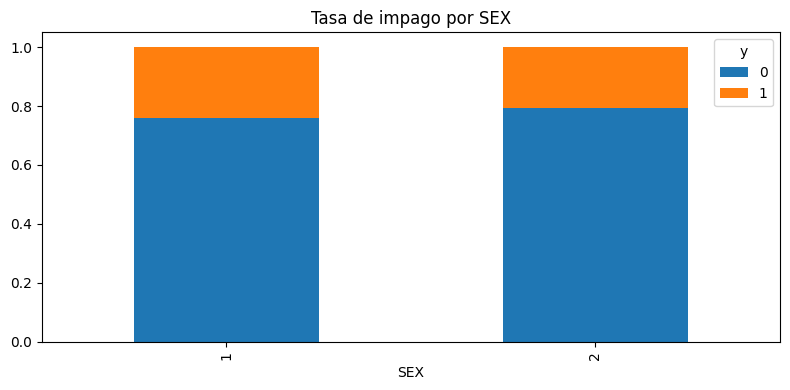


===== EDUCATION =====
EDUCATION
1    0.353
2    0.468
3    0.164
4    0.016
Name: proportion, dtype: float64
Chi-cuadrado p-value: 0.00000 -> asociada


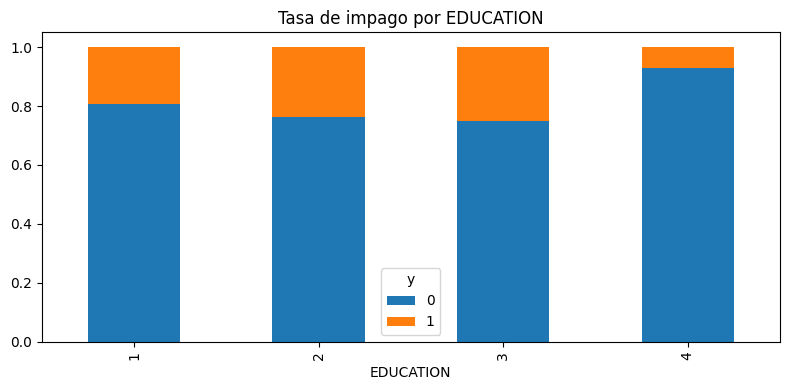


===== MARRIAGE =====
MARRIAGE
1    0.455
2    0.532
3    0.013
Name: proportion, dtype: float64
Chi-cuadrado p-value: 0.00000 -> asociada


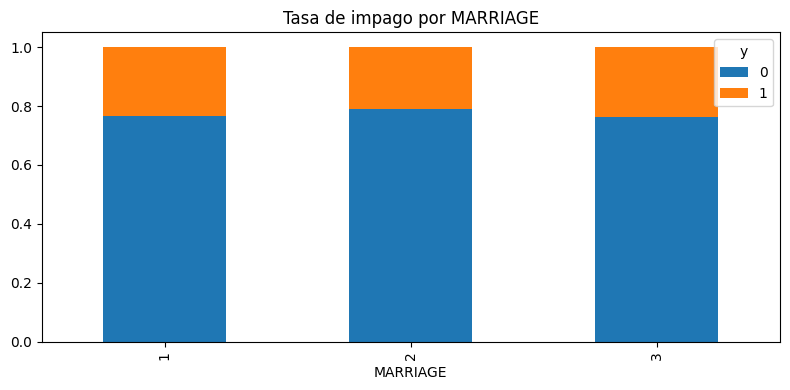


===== PAY_1 =====
PAY_1
-2    0.092
-1    0.190
 0    0.491
 1    0.123
 2    0.089
 3    0.011
 4    0.003
 5    0.001
 6    0.000
 7    0.000
 8    0.001
Name: proportion, dtype: float64
Chi-cuadrado p-value: 0.00000 -> asociada


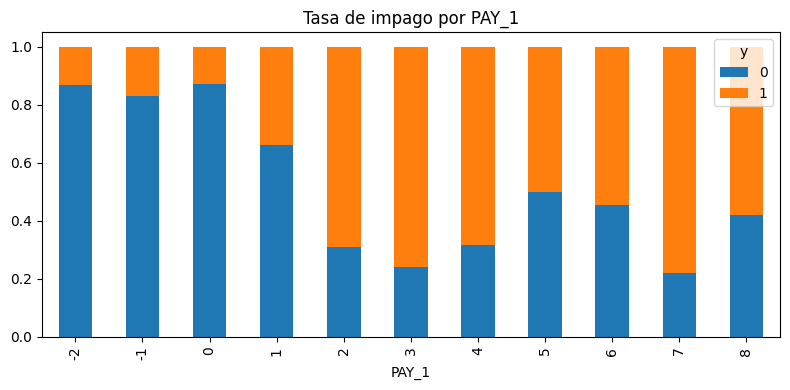


===== PAY_2 =====
PAY_2
-2    0.126
-1    0.202
 0    0.524
 1    0.001
 2    0.131
 3    0.011
 4    0.003
 5    0.001
 6    0.000
 7    0.001
 8    0.000
Name: proportion, dtype: float64
Chi-cuadrado p-value: 0.00000 -> asociada


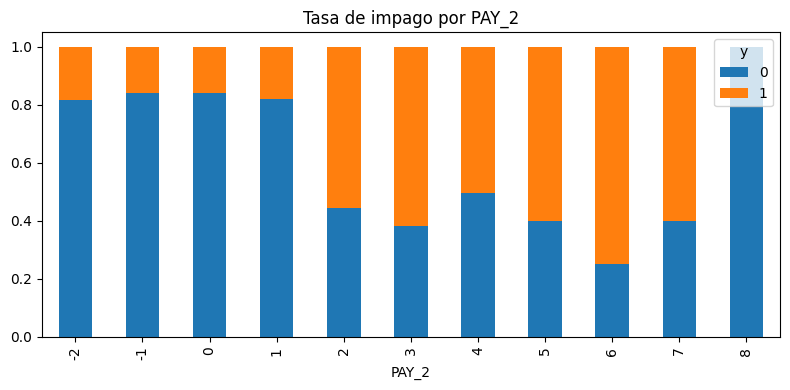


===== PAY_3 =====
PAY_3
-2    0.136
-1    0.198
 0    0.525
 1    0.000
 2    0.127
 3    0.008
 4    0.003
 5    0.001
 6    0.001
 7    0.001
 8    0.000
Name: proportion, dtype: float64
Chi-cuadrado p-value: 0.00000 -> asociada


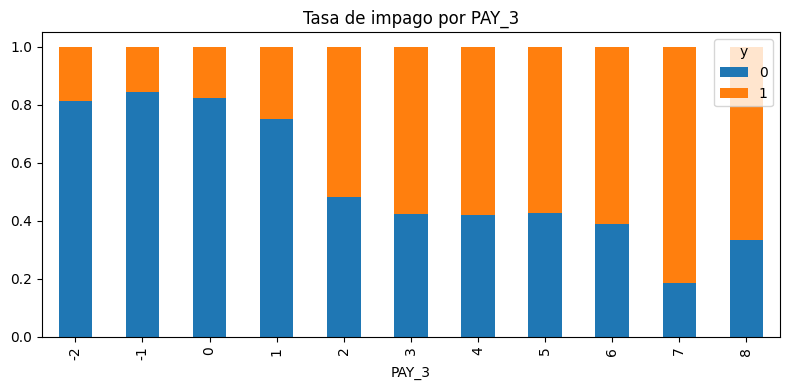


===== PAY_4 =====
PAY_4
-2    0.145
-1    0.190
 0    0.548
 1    0.000
 2    0.105
 3    0.006
 4    0.002
 5    0.001
 6    0.000
 7    0.002
 8    0.000
Name: proportion, dtype: float64
Chi-cuadrado p-value: 0.00000 -> asociada


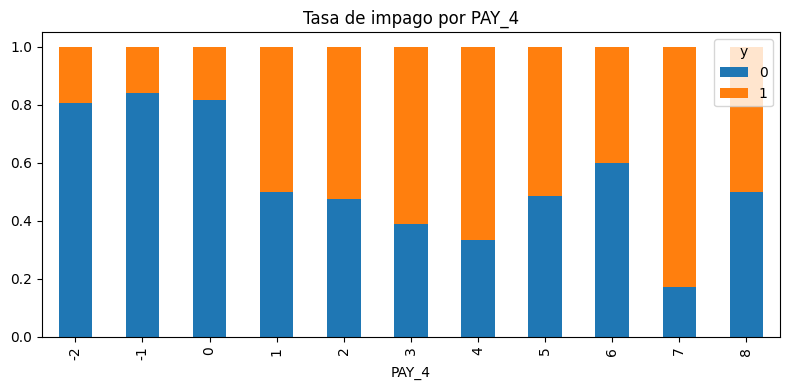


===== PAY_5 =====
PAY_5
-2    0.152
-1    0.185
 0    0.565
 2    0.088
 3    0.006
 4    0.003
 5    0.001
 6    0.000
 7    0.002
 8    0.000
Name: proportion, dtype: float64
Chi-cuadrado p-value: 0.00000 -> asociada


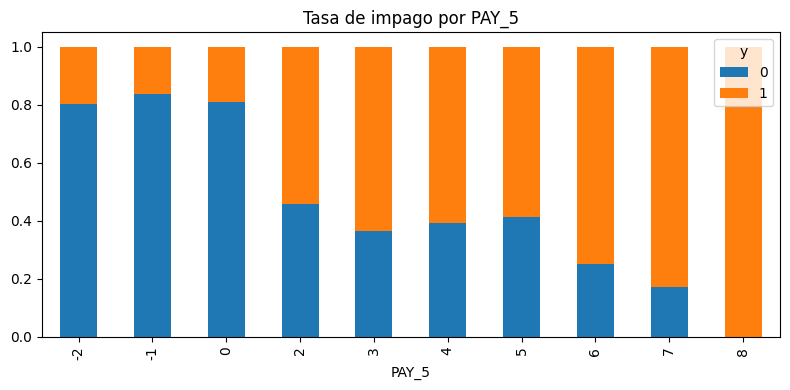


===== PAY_6 =====
PAY_6
-2    0.163
-1    0.191
 0    0.543
 2    0.092
 3    0.006
 4    0.002
 5    0.000
 6    0.001
 7    0.002
 8    0.000
Name: proportion, dtype: float64
Chi-cuadrado p-value: 0.00000 -> asociada


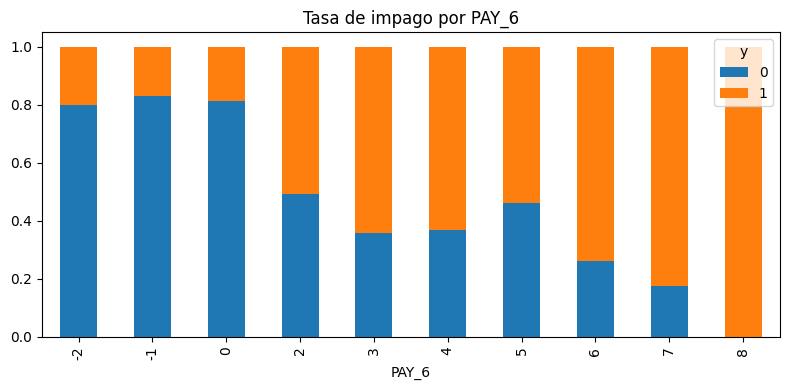

In [11]:
def analisis_categorica(col):
    print(f"\n===== {col} =====")
    print(df[col].value_counts(normalize=True, dropna=False).round(3).sort_index())

    ctabla = pd.crosstab(df[col], df['y'], margins=True).round(3)
    c, p, dof, expected = chi2_contingency(ctabla.iloc[:-1, :-1])
    print(f"Chi-cuadrado p-value: {p:.5f}", "-> asociada" if p < 0.05 else "-> no asociada")

    # Gráfico de tasa de impago por categoría
    pd.crosstab(df[col], df['y'], normalize=0).round(3).plot(
        kind='bar', stacked=True, figsize=(8, 4), title=f'Tasa de impago por {col}')
    plt.tight_layout(); plt.show()

for col in cat_features:
    analisis_categorica(col)

## ANÁLISIS UNIVARIANTE - CONTINUAS (ANOVA)


===== LIMIT_BAL =====


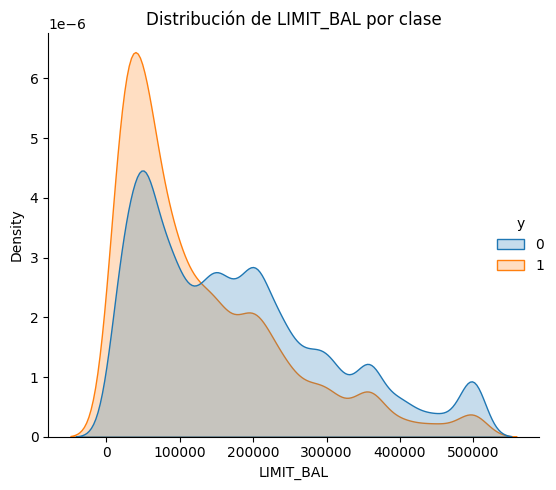

ANOVA p-value: 0.00000 → discrimina

===== AGE =====


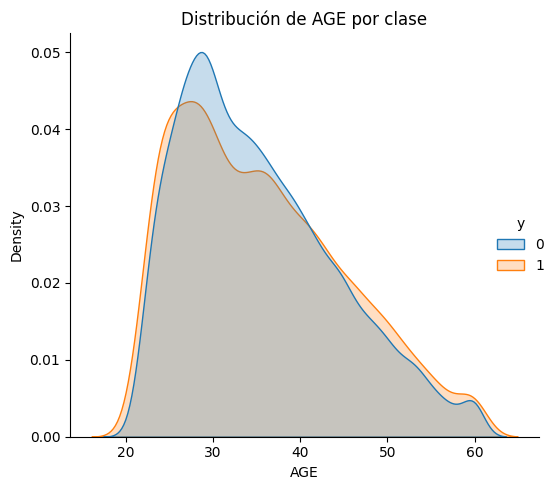

ANOVA p-value: 0.01614 → discrimina

===== BILL_AMT1 =====


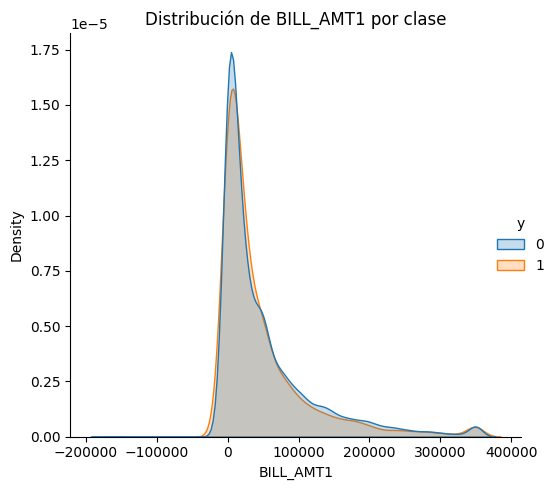

ANOVA p-value: 0.00067 → discrimina

===== BILL_AMT2 =====


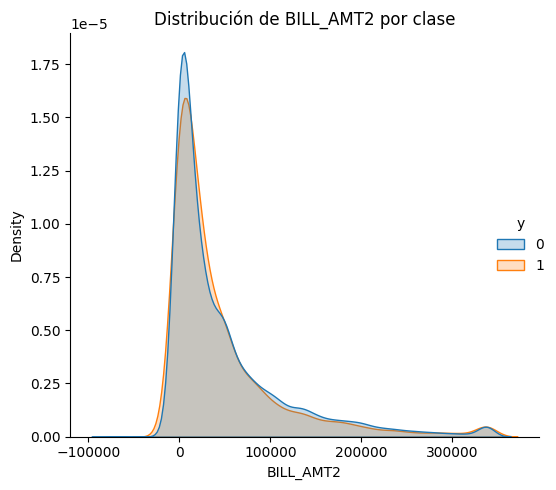

ANOVA p-value: 0.01396 → discrimina

===== BILL_AMT3 =====


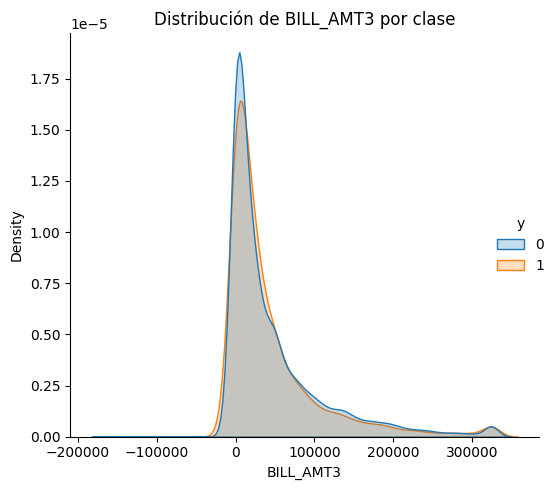

ANOVA p-value: 0.01477 → discrimina

===== BILL_AMT4 =====


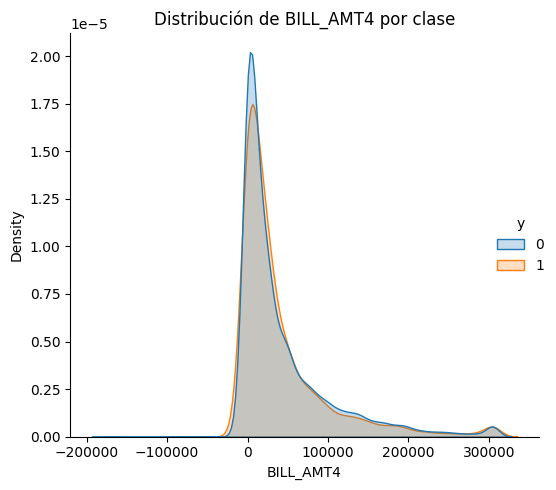

ANOVA p-value: 0.07856 → no discrimina

===== BILL_AMT5 =====


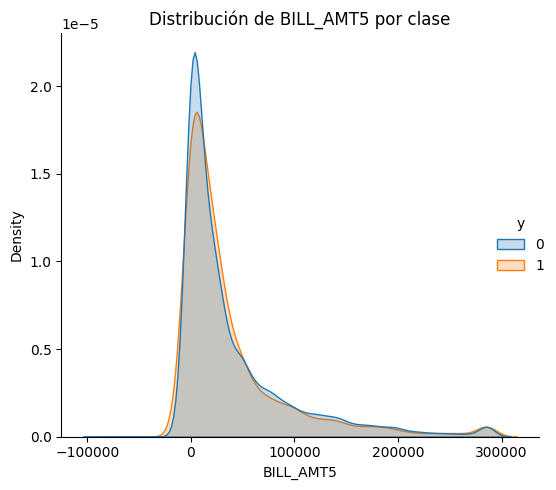

ANOVA p-value: 0.24163 → no discrimina

===== BILL_AMT6 =====


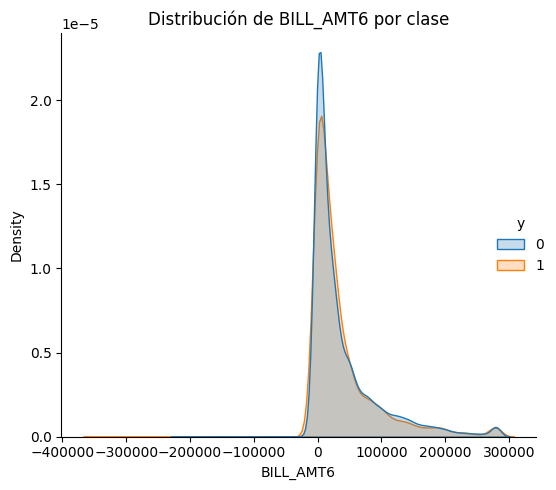

ANOVA p-value: 0.35212 → no discrimina

===== PAY_AMT1 =====


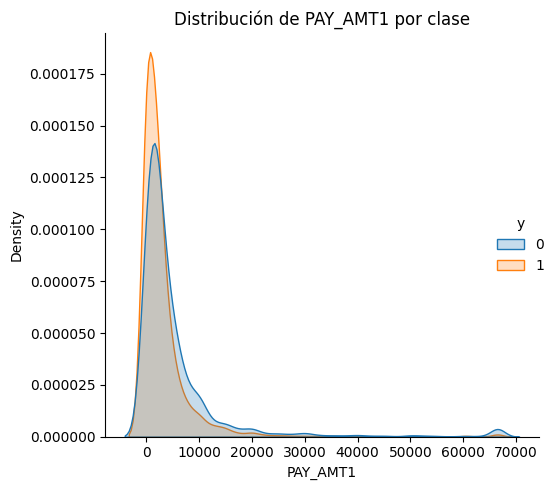

ANOVA p-value: 0.00000 → discrimina

===== PAY_AMT2 =====


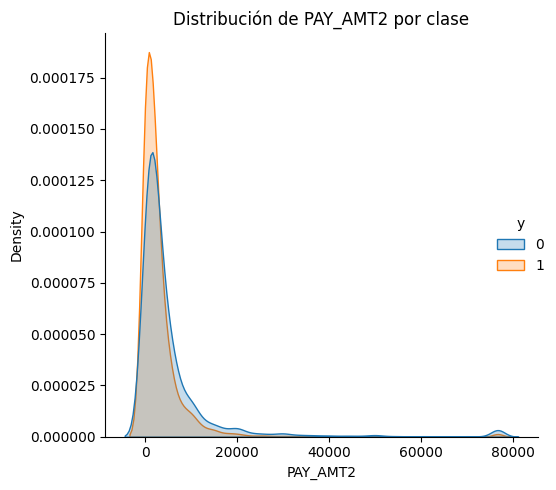

ANOVA p-value: 0.00000 → discrimina

===== PAY_AMT3 =====


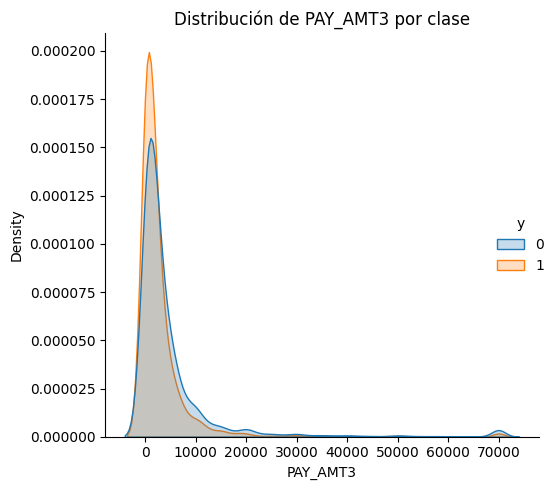

ANOVA p-value: 0.00000 → discrimina

===== PAY_AMT4 =====


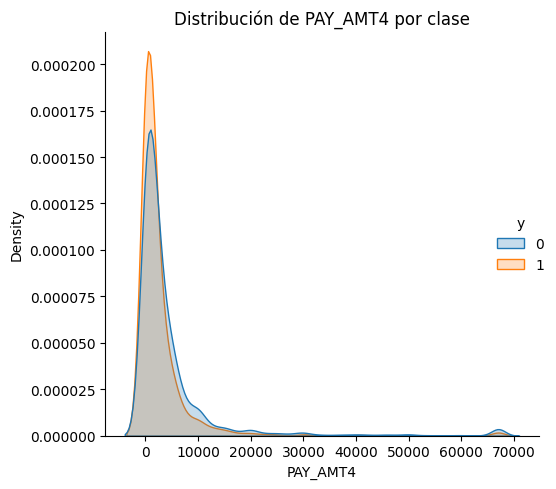

ANOVA p-value: 0.00000 → discrimina

===== PAY_AMT5 =====


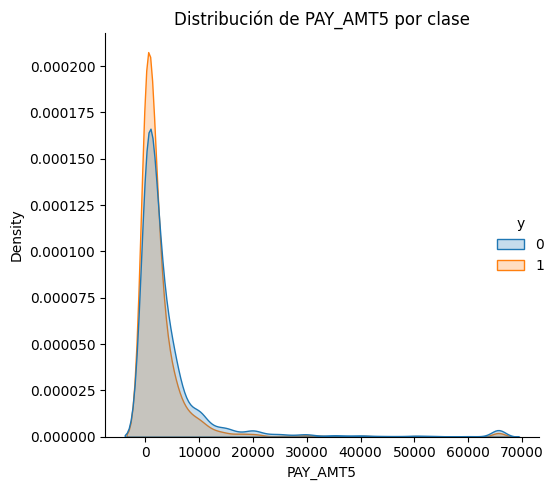

ANOVA p-value: 0.00000 → discrimina

===== PAY_AMT6 =====


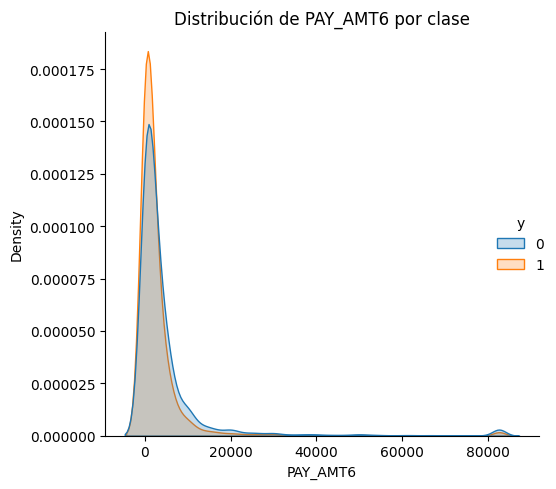

ANOVA p-value: 0.00000 → discrimina

===== util_limite =====


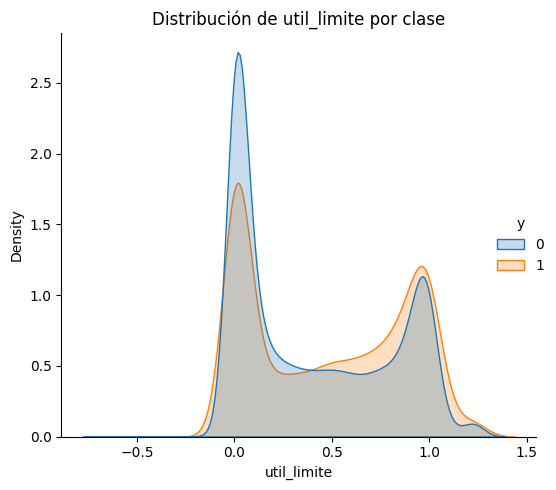

ANOVA p-value: 0.00000 → discrimina

===== util_limite_media =====


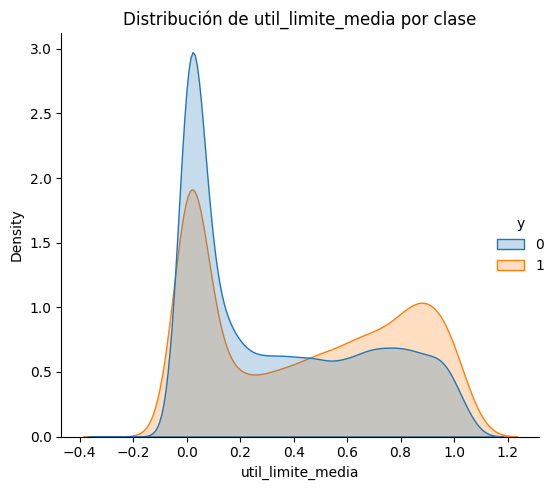

ANOVA p-value: 0.00000 → discrimina

===== esfuerzo_pago =====


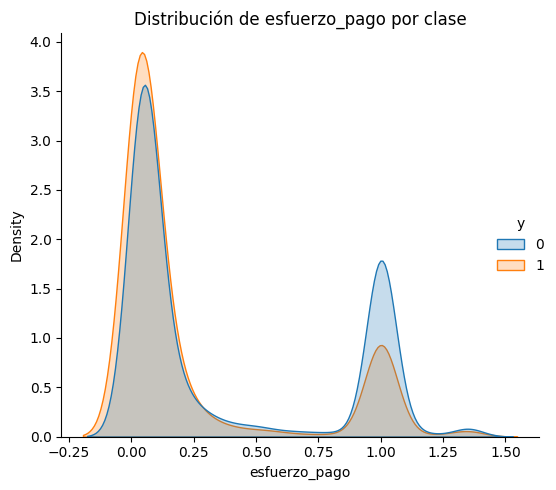

ANOVA p-value: 0.39371 → no discrimina

===== esfuerzo_pago_medio =====


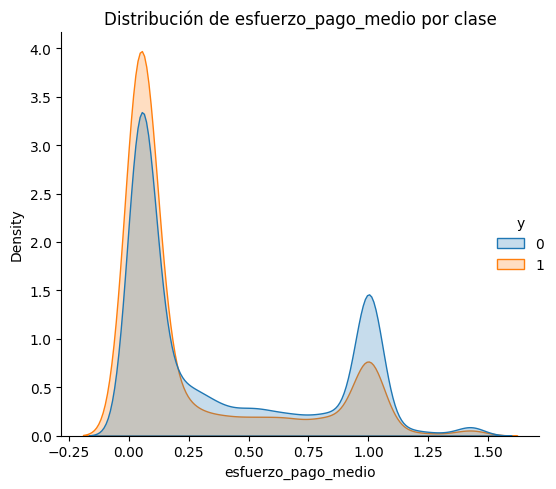

ANOVA p-value: 0.00097 → discrimina

===== tendencia_retraso =====


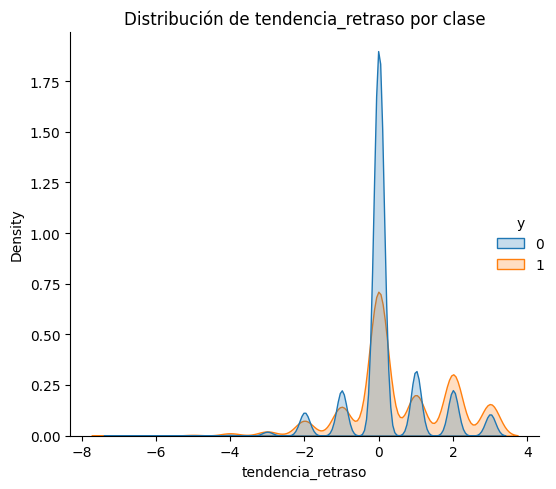

ANOVA p-value: 0.00000 → discrimina

===== meses_en_retraso =====


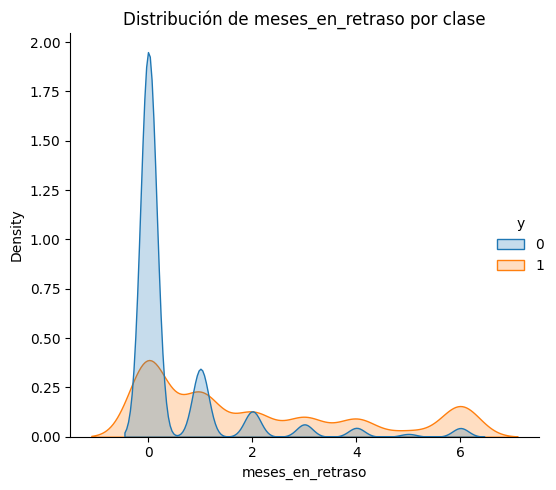

ANOVA p-value: 0.00000 → discrimina


In [12]:
def analisis_continua(col, log_transform=False):
    print(f"\n===== {col} =====")
    x = np.log1p(df[col] - df[col].min() + 1) if log_transform else df[col]
    x = x.clip(upper=x.quantile(0.99))   # solo para el grafico: los cocientes tienen colas largas

    sns.displot(x=x, kind='kde', fill=True, hue=df['y'], common_norm=False)
    plt.title(f'Distribución de {col} por clase'); plt.tight_layout(); plt.show()

    fvalue, pvalue = f_oneway(df.loc[df['y'] == 0, col].dropna(), df.loc[df['y'] == 1, col].dropna())
    print(f"ANOVA p-value: {pvalue:.5f}", "→ discrimina" if pvalue < 0.05 else "→ no discrimina")

for col in num_features:
    analisis_continua(col)

## SELECCIÓN DE VARIABLES - Split train/test estratificado

In [13]:
df_train, df_test = train_test_split(df, stratify=df['y'], test_size=0.2, random_state=RANDOM_SEED)

print(f"\nTrain: {df_train.shape[0]} | tasa impago: {df_train['y'].mean():.3f}")
print(f"Test:  {df_test.shape[0]} | tasa impago: {df_test['y'].mean():.3f}")


Train: 24000 | tasa impago: 0.221
Test:  6000 | tasa impago: 0.221


## DETECCIÓN Y TRATAMIENTO DE OUTLIERS (winsorización p1/p99)

Las variables continuas financieras (`LIMIT_BAL`, importes de factura y de pago)
tienen colas muy largas. Se hace un **diagnóstico por regla IQR (1.5·IQR)** para
cuantificar el peso de los atípicos y después una **winsorización suave a p1/p99**:
los extremos se recortan al percentil, **no se eliminan filas** (en banca no se
descarta a un cliente por ser atípico).

Los límites se ajustan **solo con el train** y se aplican al test con esos mismos
valores, para no filtrar información del test. Se hace **después del split** por
esa razón.

> Nota metodológica: el scorecard usa WOE (`optbinning`), que ya agrupa los
> extremos en bins; la winsorización es una salvaguarda adicional que además
> beneficia al *challenger* XGBoost.

In [14]:
cols_outliers = ['LIMIT_BAL', 'AGE',
                 'BILL_AMT1','BILL_AMT2','BILL_AMT3','BILL_AMT4','BILL_AMT5','BILL_AMT6',
                 'PAY_AMT1','PAY_AMT2','PAY_AMT3','PAY_AMT4','PAY_AMT5','PAY_AMT6']

# Diagnóstico por regla IQR (1.5*IQR) sobre el train
print('=== Diagnóstico de outliers en train (regla IQR 1.5) ===')
print(f'{"variable":<12}{"% outliers":>12}{"min":>14}{"max":>14}')
for col in cols_outliers:
    q1, q3 = df_train[col].quantile(0.25), df_train[col].quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5*iqr, q3 + 1.5*iqr
    pct = ((df_train[col] < low) | (df_train[col] > high)).mean() * 100
    print(f'{col:<12}{pct:>11.2f}%{df_train[col].min():>14.0f}{df_train[col].max():>14.0f}')

# Capping p1/p99 ajustada SOLO con train, aplicada a ambos
limites_winsor = {}
for col in cols_outliers:
    p1, p99 = df_train[col].quantile(0.01), df_train[col].quantile(0.99)
    limites_winsor[col] = (float(p1), float(p99))
    df_train[col] = df_train[col].clip(lower=p1, upper=p99)
    df_test[col]  = df_test[col].clip(lower=p1, upper=p99)

print(f'\nWinsorización p1/p99 aplicada a {len(cols_outliers)} variables continuas.')
print('Límites ajustados con train; filas conservadas -> '
      f'train: {df_train.shape[0]}, test: {df_test.shape[0]}')

=== Diagnóstico de outliers en train (regla IQR 1.5) ===
variable      % outliers           min           max
LIMIT_BAL          0.56%         10000       1000000
AGE                0.85%            21            79
BILL_AMT1          8.08%       -154973        964511
BILL_AMT2          8.07%        -67526        983931
BILL_AMT3          8.31%       -157264       1664089
BILL_AMT4          8.96%        -81334        891586
BILL_AMT5          9.27%        -81334        927171
BILL_AMT6          8.97%       -150953        961664
PAY_AMT1           8.99%             0        423903
PAY_AMT2           8.82%             0       1684259
PAY_AMT3           8.67%             0        896040
PAY_AMT4           9.95%             0        432130
PAY_AMT5           9.90%             0        426529
PAY_AMT6           9.76%             0        528666

Winsorización p1/p99 aplicada a 14 variables continuas.
Límites ajustados con train; filas conservadas -> train: 24000, test: 6000


## VARIABLES PROTEGIDAS

El análisis de equidad se desarrolla **íntegro en el Anexo 3**
(`03_fairness`), sobre esta misma scorecard y con el mismo preprocesado,
partición y semilla: Disparate Impact, brechas de error por grupo,
estabilidad del veredicto entre particiones y medición del riesgo de
discriminación indirecta (variables proxy).

Aquí solo se aplica su conclusión: el modelo final **excluye la variable
`SEX`** por cumplimiento de la Directiva 2004/113/CE. El análisis no se
duplica en este notebook para que exista una única fuente de cifras de
equidad en todo el trabajo.


In [15]:
# El modelo final EXCLUYE las variables protegidas.
# Justificacion y metricas: Anexo 3 (03_fairness).
variables_protegidas = ['SEX']

cat_features = [c for c in cat_features   if c not in variables_protegidas]
list_variables = [c for c in list_variables if c not in variables_protegidas]

print(f"-> Modelo final excluye {variables_protegidas}. "
      f"Variables candidatas: {len(list_variables)}")


-> Modelo final excluye ['SEX']. Variables candidatas: 28


## TRAMIFICACIÓN, AGRUPACIÓN Y TRANSFORMACIÓN WOE (optbinning)

Las variables derivadas entran como candidatas numéricas junto a las originales y se
someten al mismo criterio de selección: se descartan las que no alcanzan un Information
Value de 0,02. No se impone monotonía: en los estados de pago, los códigos negativos y el
cero recogen situaciones no ordenables entre sí.

In [16]:
X = df_train[list_variables]
Y = df_train['y'].values

selection_criteria = {'iv': {'min': 0.02}}   # IV mínimo para seleccionar variable

binning_process = BinningProcess(
    min_bin_size=0.10,
    max_n_bins=5,
    special_codes=None,
    categorical_variables=cat_features,
    variable_names=list_variables,
    selection_criteria=selection_criteria
)

binning_process.fit(X, Y)

# Resumen de IV por variable (ordenado)
print("\n=== Information Value por variable ===")
print(binning_process.summary().sort_values('iv', ascending=False))

# Tabla de binning de la variable más predictiva (PAY_1 = historial reciente)
print("\n=== Binning table de PAY_1 ===")
print(binning_process.get_binned_variable('PAY_1').binning_table.build())

# Variables seleccionadas
print("\nVariables seleccionadas:", binning_process.get_support(names=True))

# Transformación WOE
df_train_woe = binning_process.transform(X, metric='woe')

X_test = df_test[list_variables]
Y_test = df_test['y'].values
df_test_woe = binning_process.transform(X_test, metric='woe')



=== Information Value por variable ===
                   name        dtype   status  selected n_bins        iv  \
2                 PAY_1  categorical  OPTIMAL      True      4  0.887299   
27     meses_en_retraso    numerical  OPTIMAL      True      3  0.803849   
3                 PAY_2  categorical  OPTIMAL      True      4  0.550943   
4                 PAY_3  categorical  OPTIMAL      True      4  0.423938   
5                 PAY_4  categorical  OPTIMAL      True      4  0.359237   
7                 PAY_6  categorical  OPTIMAL      True      4  0.287916   
26    tendencia_retraso    numerical  OPTIMAL      True      4  0.264862   
16             PAY_AMT1    numerical  OPTIMAL      True      5  0.184008   
8             LIMIT_BAL    numerical  OPTIMAL      True      5  0.173994   
17             PAY_AMT2    numerical  OPTIMAL      True      5  0.166159   
25  esfuerzo_pago_medio    numerical  OPTIMAL      True      4  0.154917   
6                 PAY_5  categorical  OPTIMAL   

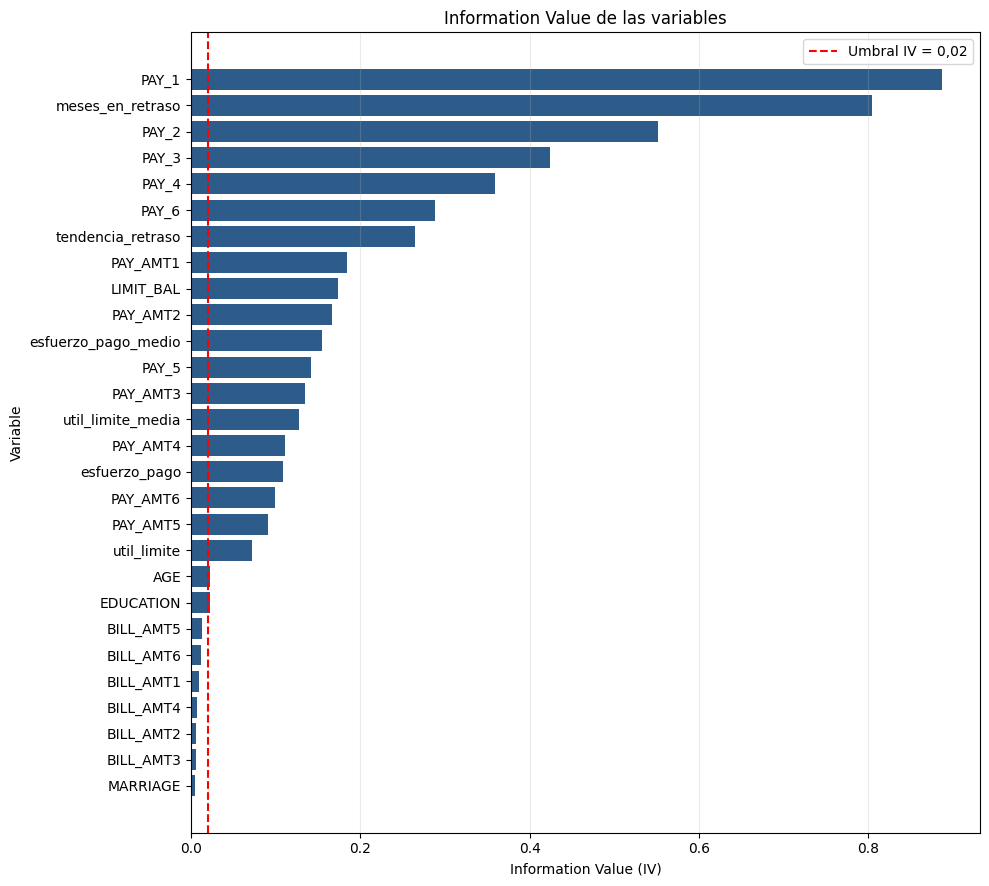

In [17]:
# Gráfico Information Value de las variables
# Resumen del IV de las variables candidatas
tabla_iv = binning_process.summary().copy()
tabla_iv = tabla_iv.dropna(subset=["iv"])
tabla_iv = tabla_iv.sort_values("iv", ascending=True)

# Gráfico de barras horizontales
fig, ax = plt.subplots(
    figsize=(10, max(7, 0.32 * len(tabla_iv)))
)

ax.barh(
    tabla_iv["name"],
    tabla_iv["iv"],
    color="#2E5C8A"
)

# Umbral mínimo de selección
ax.axvline(
    x=0.02,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label="Umbral IV = 0,02"
)

ax.set_xlabel("Information Value (IV)")
ax.set_ylabel("Variable")
ax.set_title("Information Value de las variables")
ax.legend()
ax.grid(axis="x", alpha=0.25)

fig.tight_layout()
plt.show()

In [18]:
# Las variables derivadas compiten con las originales bajo el mismo criterio:
# entran en el scorecard las que alcanzan un Information Value de 0,02.
resumen_iv = binning_process.summary().set_index('name')
seleccionadas_bp = set(binning_process.get_support(names=True))
tabla_derivadas = pd.DataFrame({
    'IV': resumen_iv.loc[VARIABLES_DERIVADAS, 'iv'].astype(float).round(4),
    'seleccionada': ['sí' if v in seleccionadas_bp else 'no' for v in VARIABLES_DERIVADAS],
}).sort_values('IV', ascending=False)
print("=== Variables derivadas frente al umbral de IV (0,02) ===")
display(tabla_derivadas)
print(f"Superan el umbral de IV {int((tabla_derivadas['seleccionada'] == 'sí').sum())} "
      f"de {len(VARIABLES_DERIVADAS)} derivadas.")

=== Variables derivadas frente al umbral de IV (0,02) ===


,IV,seleccionada
name,,
meses_en_retraso,0.8038,sí
tendencia_retraso,0.2649,sí
esfuerzo_pago_medio,0.1549,sí
util_limite_media,0.1279,sí
esfuerzo_pago,0.1085,sí
util_limite,0.0720,sí


Superan el umbral de IV 6 de 6 derivadas.


## ESTIMACIÓN DEL MODELO - Scorecard (champion)

Con la convención de optbinning, un WOE mayor indica menos riesgo, así que en un scorecard
todos los coeficientes deberían ser **negativos**. Un coeficiente positivo no se puede
interpretar: el tramo correspondiente sumaría puntos en sentido contrario al riesgo.

El modelo se construye en tres pasos:

1. Se ajusta con todas las candidatas que superan el IV, para ver qué coeficientes salen
   positivos y con qué otras variables están relacionados.
2. Se descartan de entrada las variables que repiten información de otra, con un criterio de
   negocio, y se ajusta el modelo. La revisión de signos se mantiene como red de seguridad.
3. Se comparan ambos procedimientos con validación cruzada para comprobar que la selección no
   cuesta capacidad predictiva.

In [19]:
def ajustar_una_vez(X_tr, y_tr, variables):
    bp = BinningProcess(min_bin_size=0.10, max_n_bins=5, special_codes=None,
                        categorical_variables=[v for v in cat_features if v in variables],
                        variable_names=list(variables),
                        selection_criteria=selection_criteria)
    sc = Scorecard(binning_process=bp,
                   estimator=LogisticRegression(solver='lbfgs', penalty='l2', max_iter=1000),
                   scaling_method='pdo_odds',
                   scaling_method_params={'pdo': 20, 'odds': 1/19, 'scorecard_points': 600})
    sc.fit(X_tr[list(variables)], y_tr)
    coef = pd.Series(sc.estimator_.coef_[0], index=sc.binning_process_.get_support(names=True))
    return sc, coef


def ajustar_scorecard(X_tr, y_tr, variables):
    """Ajusta el scorecard quitando de una en una las variables con coeficiente positivo."""
    variables = list(variables)
    eliminadas = []
    while True:
        sc, coef = ajustar_una_vez(X_tr, y_tr, variables)
        if (coef <= 0).all():
            return sc, eliminadas
        peor = coef.idxmax()
        eliminadas.append((peor, round(float(coef.max()), 4)))
        variables.remove(peor)


# Todas las candidatas que superan el IV
_, coef_todas = ajustar_una_vez(df_train, Y, list_variables)
positivas = coef_todas[coef_todas > 0].sort_values(ascending=False)
en_modelo = list(coef_todas.index)
corr = df_train[en_modelo].corr(method='spearman')

print("=== Paso 1: coeficientes con signo positivo usando todas las candidatas ===")
for v, c in positivas.items():
    otra = corr[v].drop(v).abs().idxmax()
    print(f"  {v:<20} {c:+.4f}   mas correlacionada con {otra} ({corr.loc[v, otra]:+.2f})")
if positivas.empty:
    print("  ninguno")

=== Paso 1: coeficientes con signo positivo usando todas las candidatas ===
  tendencia_retraso    +0.1331   mas correlacionada con PAY_1 (+0.48)
  PAY_2                +0.0728   mas correlacionada con PAY_3 (+0.80)
  PAY_5                +0.0398   mas correlacionada con PAY_4 (+0.82)


Las variables con el signo invertido no carecen de información: repiten la de otra variable
del modelo, y la regresión las usa para compensar. Por eso se descartan de entrada las que son
redundantes por construcción (lista `VARIABLES_REDUNDANTES` de `config_riesgo.py`):

- **PAY_2 a PAY_6**: el historial de pagos lo resumen PAY_1, el último mes y la señal más
  fuerte, y `meses_en_retraso`, que cuenta los meses con retraso del semestre.
- **tendencia_retraso**: se calcula como PAY_1 − PAY_6.
- **util_limite y esfuerzo_pago**: las versiones del último mes las recogen sus medias del
  semestre, que distinguen al titular apalancado de forma crónica del que tuvo un mes malo.

El modelo se queda así con lo más reciente (PAY_1) y lo acumulado (las tres derivadas del
semestre), y no con variables intermedias que combinan ambas cosas.

In [20]:
# Seleccion por criterio de negocio, con la revision de signos como red de seguridad
candidatas = [v for v in list_variables if v not in VARIABLES_REDUNDANTES]
tarjeta, eliminadas = ajustar_scorecard(df_train, Y, candidatas)
binning_process = tarjeta.binning_process_

print(f"Candidatas tras quitar las redundantes: {len(candidatas)}")
print("Variables eliminadas por signo positivo:", eliminadas or "ninguna")

# A partir de aqui se usan las columnas que espera el modelo final
X = df_train[binning_process.variable_names]
X_test = df_test[binning_process.variable_names]

print("\n=== Coeficientes del scorecard final ===")
print(tarjeta.table(style='detailed')[['Variable', 'Coefficient']].drop_duplicates().to_string(index=False))
print(f"\nVariables en el modelo: {len(binning_process.get_support(names=True))}")

Candidatas tras quitar las redundantes: 20
Variables eliminadas por signo positivo: ninguna

=== Coeficientes del scorecard final ===
           Variable  Coefficient
          EDUCATION    -0.122150
              PAY_1    -0.632834
          LIMIT_BAL    -0.211500
                AGE    -0.343038
           PAY_AMT1    -0.049712
           PAY_AMT2    -0.196477
           PAY_AMT3    -0.238942
           PAY_AMT4    -0.227897
           PAY_AMT5    -0.100687
           PAY_AMT6    -0.177582
  util_limite_media    -0.380362
esfuerzo_pago_medio    -0.269911
   meses_en_retraso    -0.378507

Variables en el modelo: 13


In [21]:
# Extracto de la tabla de puntos del scorecard
# Obtener la tabla de puntos del modelo final
tabla_puntos_completa = tarjeta.table(style="summary")

# Seleccionar dos variables relevantes
variables_extracto = [
    "PAY_1",
    "meses_en_retraso"
]

# Construir la tabla para incluirla en la memoria
tabla_extracto = (
    tabla_puntos_completa.loc[
        tabla_puntos_completa["Variable"].isin(variables_extracto),
        ["Variable", "Bin", "Points"]
    ]
    .rename(columns={
        "Bin": "Tramo",
        "Points": "Puntos"
    })
    .reset_index(drop=True)
)

# Redondear los puntos a dos decimales para facilitar la lectura
tabla_extracto["Puntos"] = tabla_extracto["Puntos"].round(2)

# Mostrar la tabla en el notebook
display(tabla_extracto)


,Variable,Tramo,Puntos
0,PAY_1,"[-2, 0]",67.67
1,PAY_1,[-1],61.29
2,PAY_1,[1],44.58
3,PAY_1,"[5, 8, 6, 4, 2, 3, 7]",17.22
4,PAY_1,Special,55.46
5,PAY_1,Missing,55.46
6,meses_en_retraso,"(-inf, 0.50)",63.88
7,meses_en_retraso,"[0.50, 1.50)",50.93
8,meses_en_retraso,"[1.50, inf)",40.44
9,meses_en_retraso,Special,55.46


## DIAGNÓSTICO DEL MODELO (dentro de muestra)


=== Matriz de confusión (train) ===
Y_pronostico      0     1    All
y                               
0             15221  3470  18691
1              2127  3182   5309
All           17348  6652  24000
F1: 0.532

AUC train:  0.7763
Gini train: 0.5527


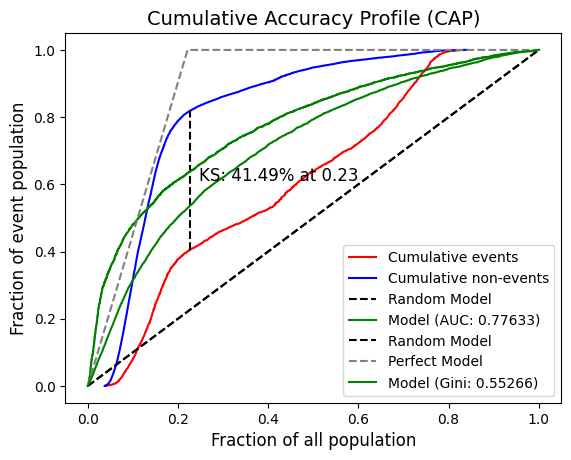

In [22]:
Y_pred = tarjeta.predict_proba(X)[:, 1]

plot_ks(Y, Y_pred)
plot_auc_roc(Y, Y_pred)
plot_cap(Y, Y_pred)

# Matriz de confusión con punto de corte = tasa media de impago
Prob_Corte = Y.mean()
df_train = df_train.copy()
df_train['Y_pronostico'] = (Y_pred >= Prob_Corte).astype(int)

tab = pd.crosstab(df_train['y'], df_train['Y_pronostico'], margins=True)
print("\n=== Matriz de confusión (train) ===")
print(tab)
print("F1:", round(f1_score(df_train['y'], df_train['Y_pronostico']), 3))
# Metricas de discriminacion en TRAIN: se comparan con las de test para
# descartar overfitting (ver tabla de validacion de la memoria).
auc_train_sc = roc_auc_score(Y, Y_pred)
print(f"\nAUC train:  {auc_train_sc:.4f}")
print(f"Gini train: {2 * auc_train_sc - 1:.4f}")


## DIAGNÓSTICO FUERA DE MUESTRA (test)


AUC test scorecard: 0.7594
Gini test scorecard: 0.5188


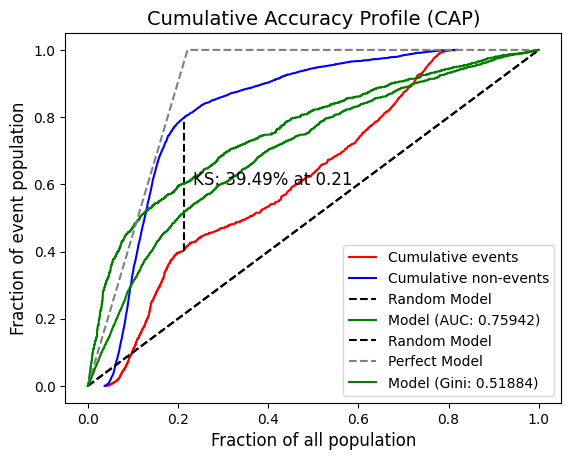

In [23]:
Y_test_pred = tarjeta.predict_proba(X_test)[:, 1]

plot_ks(Y_test, Y_test_pred)
plot_auc_roc(Y_test, Y_test_pred)
plot_cap(Y_test, Y_test_pred)

auc_test_sc = roc_auc_score(Y_test, Y_test_pred)
print(f"\nAUC test scorecard: {auc_test_sc:.4f}")
print(f"Gini test scorecard: {2 * auc_test_sc - 1:.4f}")

## CALIBRACIÓN DE LA PROBABILIDAD Y ROBUSTEZ DE LAS MÉTRICAS

El AUC mide la capacidad de **discriminación** (ordenar clientes de menor a mayor
riesgo), pero un modelo de PD para IFRS 9 debe estar además **calibrado**: una PD
estimada del 20 % debe corresponder a una frecuencia de impago observada próxima al
20 %, ya que la provisión (ECL = PD × LGD × EAD) depende del valor absoluto de la PD.

Se evalúa la calibración con un diagrama de fiabilidad y el Brier score, y se acompaña
el AUC de un intervalo de confianza bootstrap para reflejar su incertidumbre.

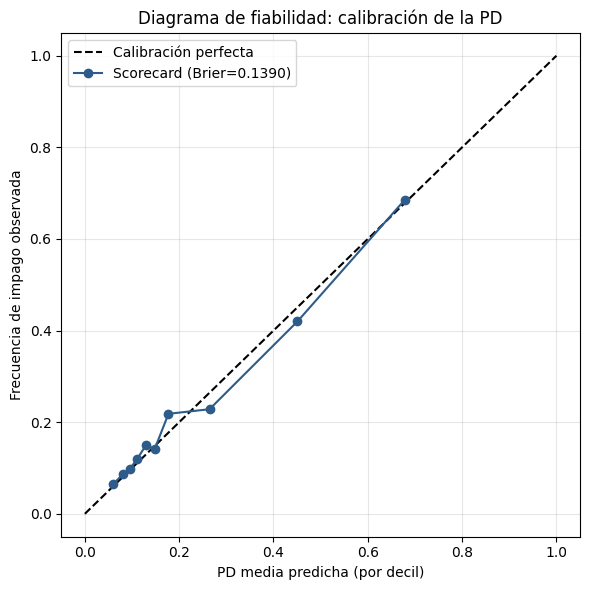

Brier score: 0.1390  (0 = perfecto; cuanto menor, mejor calibrado)
Si los puntos siguen la diagonal, la PD esta bien calibrada y las provisiones IFRS 9 son fiables.
Una desviacion sistematica indicaria necesidad de recalibrar
(p. ej. regresion isotonica o de Platt) antes de usar el modelo para provisionar.

AUC test: 0.7594  |  IC 95% bootstrap: [0.7433, 0.7745]
El intervalo cuantifica la incertidumbre del AUC en la muestra de test.


In [24]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

# Diagrama de fiabilidad (reliability plot)
frac_pos, mean_pred = calibration_curve(Y_test, Y_test_pred, n_bins=10, strategy='quantile')
brier = brier_score_loss(Y_test, Y_test_pred)

plt.figure(figsize=(6, 6))
plt.plot([0, 1], [0, 1], 'k--', label='Calibración perfecta')
plt.plot(mean_pred, frac_pos, 'o-', color='#2E5C8A', label=f'Scorecard (Brier={brier:.4f})')
plt.xlabel('PD media predicha (por decil)')
plt.ylabel('Frecuencia de impago observada')
plt.title('Diagrama de fiabilidad: calibración de la PD')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

print(f"Brier score: {brier:.4f}  (0 = perfecto; cuanto menor, mejor calibrado)")
print("Si los puntos siguen la diagonal, la PD esta bien calibrada y las provisiones IFRS 9 son fiables.")
print("Una desviacion sistematica indicaria necesidad de recalibrar")
print("(p. ej. regresion isotonica o de Platt) antes de usar el modelo para provisionar.")

# Intervalo de confianza bootstrap del AUC
rng = np.random.default_rng(RANDOM_SEED)
aucs_boot = []
n = len(Y_test)
Y_test_arr = np.asarray(Y_test)
for _ in range(1000):
    idx = rng.integers(0, n, n)
    if len(np.unique(Y_test_arr[idx])) < 2:
        continue
    aucs_boot.append(roc_auc_score(Y_test_arr[idx], Y_test_pred[idx]))
aucs_boot = np.array(aucs_boot)
ic_low, ic_high = np.percentile(aucs_boot, [2.5, 97.5])
print(f"\nAUC test: {auc_test_sc:.4f}  |  IC 95% bootstrap: [{ic_low:.4f}, {ic_high:.4f}]")
print("El intervalo cuantifica la incertidumbre del AUC en la muestra de test.")

## VALIDACIÓN ROBUSTA - Cross-validation estratificada

In [25]:
# Validacion cruzada repitiendo todo el procedimiento en cada particion,
# para el modelo desplegado y, como referencia, para el que usa todas las candidatas
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
auc_folds, auc_folds_todas = [], []
for train_idx, val_idx in cv.split(df_train, Y):
    tr_k, val_k = df_train.iloc[train_idx], df_train.iloc[val_idx]
    for variables, lista in ((candidatas, auc_folds), (list_variables, auc_folds_todas)):
        sc_k, _ = ajustar_scorecard(tr_k, Y[train_idx], variables)
        p = sc_k.predict_proba(val_k[sc_k.binning_process_.variable_names])[:, 1]
        lista.append(roc_auc_score(Y[val_idx], p))
auc_folds, auc_folds_todas = np.array(auc_folds), np.array(auc_folds_todas)

print("AUC por particion (5-fold CV), modelo desplegado:")
for k, auc_k in enumerate(auc_folds, start=1):
    print(f"  Fold {k}: {auc_k:.4f}")
print(f"\nAUC CV scorecard (media): {auc_folds.mean():.4f}")
print(f"AUC CV scorecard (std):   {auc_folds.std():.4f}")
print(f"Resumen: {auc_folds.mean():.4f} ± {auc_folds.std():.4f}")

perdida = auc_folds_todas.mean() - auc_folds.mean()
print(f"\nReferencia con todas las candidatas: {auc_folds_todas.mean():.4f} ± {auc_folds_todas.std():.4f}")
print(f"Diferencia: {perdida:+.4f} de AUC frente a una dispersion entre particiones de {auc_folds.std():.4f}")
if perdida < auc_folds.std():
    print("La seleccion por criterio de negocio no cuesta capacidad predictiva apreciable:")
    print("la diferencia es menor que la variabilidad entre particiones.")
else:
    print("ATENCION: la seleccion cuesta mas que la variabilidad entre particiones.")

AUC por particion (5-fold CV), modelo desplegado:
  Fold 1: 0.7756
  Fold 2: 0.7778
  Fold 3: 0.7506
  Fold 4: 0.7873
  Fold 5: 0.7736

AUC CV scorecard (media): 0.7730
AUC CV scorecard (std):   0.0121
Resumen: 0.7730 ± 0.0121

Referencia con todas las candidatas: 0.7739 ± 0.0117
Diferencia: +0.0009 de AUC frente a una dispersion entre particiones de 0.0121
La seleccion por criterio de negocio no cuesta capacidad predictiva apreciable:
la diferencia es menor que la variabilidad entre particiones.


## ESTABILIDAD DEL SCORE - Population Stability Index (PSI)

El PSI cuantifica si la distribución del score cambia entre dos poblaciones. Conviene
precisar su alcance en este punto: train y test proceden de una **partición aleatoria del
mismo corte temporal**, de modo que un PSI próximo a cero es el resultado esperado por
construcción. Verifica la coherencia de la partición, **no estima la deriva futura**.

Su función aquí es dejar implementado el cálculo que, en producción, se aplicaría entre la
población de desarrollo y cada nueva ventana mensual, con los umbrales habituales de 0,10
para revisión y 0,25 para recalibración. La validación desplazada en el tiempo de unas
celdas más abajo es la que aporta evidencia temporal.

In [26]:
def calcular_psi(esperado, observado, n_bins=10):
    """PSI entre dos distribuciones de score usando deciles del esperado (train)."""
    bordes = np.percentile(esperado, np.linspace(0, 100, n_bins + 1))
    bordes[0], bordes[-1] = -np.inf, np.inf
    e_perc = np.histogram(esperado, bins=bordes)[0] / len(esperado)
    o_perc = np.histogram(observado, bins=bordes)[0] / len(observado)
    e_perc = np.clip(e_perc, 1e-6, None)
    o_perc = np.clip(o_perc, 1e-6, None)
    return np.sum((o_perc - e_perc) * np.log(o_perc / e_perc))

score_train = tarjeta.score(X)
score_test  = tarjeta.score(X_test)
psi = calcular_psi(score_train, score_test)

print(f"PSI (train vs test): {psi:.4f}")
print("-> Particion aleatoria del mismo corte: un PSI proximo a cero es lo esperado")
print("   por construccion. Verifica la particion, no la estabilidad futura.")

PSI (train vs test): 0.0030
-> Particion aleatoria del mismo corte: un PSI proximo a cero es lo esperado
   por construccion. Verifica la particion, no la estabilidad futura.


## MONITORIZACIÓN POR VARIABLE Y BACKTESTING DE LA CALIBRACIÓN

El seguimiento de un modelo en producción tiene dos mitades, y el PSI solo cubre una:

- **Estabilidad de la población**: PSI del score y de cada variable seleccionada. Detecta
  que la cartera ha cambiado, pero no que el modelo haya dejado de acertar.
- **Backtesting de la calibración**: tasa de impago observada frente a PD media predicha,
  por decil. Detecta la pérdida de acierto, pero solo puede calcularse cuando el
  desenlace de la ventana ya es observable.

Se dejan implementadas las dos sobre la partición disponible.

In [27]:
def psi_variable(referencia, actual, n_tramos=10):
    """PSI de una variable numerica, con los NaN en su propio tramo."""
    ref = pd.Series(referencia, dtype=float)
    act = pd.Series(actual, dtype=float)
    cortes = np.unique(np.nanquantile(ref, np.linspace(0, 1, n_tramos + 1)))
    if len(cortes) < 2:
        return 0.0
    cortes[0], cortes[-1] = -np.inf, np.inf

    def proporciones(s):
        h = np.append(np.histogram(s.dropna(), cortes)[0], s.isna().sum())
        return np.clip(h.astype(float) / max(len(s), 1), 1e-6, None)

    p_r, p_a = proporciones(ref), proporciones(act)
    return float(np.sum((p_a - p_r) * np.log(p_a / p_r)))


def lectura_psi(v):
    return 'recalibrar' if v >= 0.25 else ('revisar' if v >= 0.10 else 'estable')


seleccionadas = list(binning_process.get_support(names=True))
informe_psi = pd.DataFrame(
    [{'variable': v, 'PSI': psi_variable(df_train[v], df_test[v])} for v in seleccionadas])
informe_psi['estado'] = informe_psi['PSI'].apply(lectura_psi)
print("=== PSI por variable seleccionada (train frente a test) ===")
display(informe_psi.sort_values('PSI', ascending=False).round(4).reset_index(drop=True))

backtest = pd.DataFrame({'pd': Y_test_pred, 'y': np.asarray(Y_test)})
backtest['decil'] = pd.qcut(backtest['pd'].rank(method='first'), 10, labels=False) + 1
backtest = backtest.groupby('decil').agg(pd_media=('pd', 'mean'),
                                         tasa_observada=('y', 'mean'),
                                         clientes=('y', 'size'))
backtest['desviacion'] = backtest['tasa_observada'] - backtest['pd_media']
print("\n=== Backtesting de la calibracion por decil de PD (test) ===")
display(backtest.round(4))

=== PSI por variable seleccionada (train frente a test) ===


,variable,PSI,estado
0,esfuerzo_pago_medio,0.0052,estable
1,PAY_AMT2,0.0052,estable
2,PAY_AMT6,0.0038,estable
3,PAY_AMT4,0.0031,estable
4,PAY_AMT5,0.0024,estable
5,PAY_AMT3,0.0024,estable
6,util_limite_media,0.0022,estable
7,LIMIT_BAL,0.0018,estable
8,PAY_AMT1,0.0017,estable
9,AGE,0.0013,estable



=== Backtesting de la calibracion por decil de PD (test) ===


,pd_media,tasa_observada,clientes,desviacion
decil,,,,
1,0.0599,0.0650,600,0.0051
2,0.0803,0.0867,600,0.0063
3,0.0949,0.0967,600,0.0018
4,0.1111,0.1200,600,0.0089
5,0.1297,0.1500,600,0.0203
6,0.1481,0.1417,600,-0.0065
7,0.1773,0.2183,600,0.0410
8,0.2643,0.2283,600,-0.0360
9,0.4508,0.4200,600,-0.0308


## VALIDACIÓN DESPLAZADA EN EL TIEMPO

El dataset no tiene fechas utilizables, pero sí **seis meses de historial ordenados en el
tiempo**. Eso permite una validación fuera de tiempo real: se construye un scorecard con la
misma metodología sobre una ventana (abril a junio para predecir julio) y se evalúa sobre las
ventanas siguientes, sin reentrenar.

Tiene tres límites que hay que declarar:

- El evento es **aproximado**: retraso de dos o más meses en un mes dado, que se codifica
  igual en todas las columnas. No es la variable objetivo del scorecard desplegado: valida
  que la relación entre historial y morosidad es estable, no el modelo concreto.
- Son **los mismos titulares** en todas las ventanas: fuera de tiempo, no fuera de población.
- La ventana de septiembre usa la columna PAY_1, **codificada de forma distinta**, de modo que
  su tasa observada no es comparable con las de las demás.

In [28]:
MESES_NOMBRE = {1: 'sep', 2: 'ago', 3: 'jul', 4: 'jun', 5: 'may', 6: 'abr'}
N_HISTORIAL = 3


def ventana(datos, t, umbral=2):
    """Variables de los N_HISTORIAL meses previos a t y evento en el mes t."""
    X_v = datos[['LIMIT_BAL', 'AGE', 'EDUCATION']].copy()
    for k, j in enumerate(range(t + 1, t + 1 + N_HISTORIAL), start=1):
        X_v[f'PAY_lag{k}']  = datos[f'PAY_{j}'].replace(1, 0)   # misma codificacion en todos
        X_v[f'BILL_lag{k}'] = datos[f'BILL_AMT{j}']
        X_v[f'PAMT_lag{k}'] = datos[f'PAY_AMT{j}']
    return X_v, (datos[f'PAY_{t}'] >= umbral).astype(int).values


cat_ventana = ['EDUCATION'] + [f'PAY_lag{k}' for k in range(1, N_HISTORIAL + 1)]
X_vref, y_vref = ventana(df_train, 3)
sc_ventana = Scorecard(
    binning_process=BinningProcess(min_bin_size=0.10, max_n_bins=5,
                                   categorical_variables=cat_ventana,
                                   variable_names=list(X_vref.columns),
                                   selection_criteria=selection_criteria),
    estimator=LogisticRegression(max_iter=1000),
    scaling_method='pdo_odds',
    scaling_method_params={'pdo': 20, 'odds': 1/19, 'scorecard_points': 600})
sc_ventana.fit(X_vref, y_vref)

p_ventana_ref = sc_ventana.predict_proba(ventana(df_test, 3)[0])[:, 1]
filas_v = []
for t in (3, 2, 1):
    X_v, y_v = ventana(df_test, t)
    p_v = sc_ventana.predict_proba(X_v)[:, 1]
    filas_v.append({
        'ventana': f'{MESES_NOMBRE[t + N_HISTORIAL]}-{MESES_NOMBRE[t + 1]} -> {MESES_NOMBRE[t]}',
        'papel':   {3: 'entrenamiento', 2: 'fuera de tiempo', 1: 'fuera de tiempo (*)'}[t],
        'tasa observada': y_v.mean(),
        'PD media':       p_v.mean(),
        'AUC':            roc_auc_score(y_v, p_v),
        'PSI del score':  calcular_psi(p_ventana_ref, p_v),
    })

print("Evaluacion sobre los titulares de test, con el scorecard entrenado en julio.\n")
display(pd.DataFrame(filas_v).round(4))
print("(*) Ventana afectada por la codificacion distinta de PAY_1.")
print("Un PSI proximo a cero con calibracion o AUC que cambian ilustra por que la")
print("estabilidad de la poblacion no garantiza la estabilidad del rendimiento.")

Evaluacion sobre los titulares de test, con el scorecard entrenado en julio.



,ventana,papel,tasa observada,PD media,AUC,PSI del score
0,abr-jun -> jul,entrenamiento,0.1385,0.1390,0.8598,0.0000
1,may-jul -> ago,fuera de tiempo,0.1460,0.1509,0.8753,0.0045
2,jun-ago -> sep,fuera de tiempo (*),0.1028,0.1576,0.8744,0.0069


(*) Ventana afectada por la codificacion distinta de PAY_1.
Un PSI proximo a cero con calibracion o AUC que cambian ilustra por que la
estabilidad de la poblacion no garantiza la estabilidad del rendimiento.


## OPTIMIZACIÓN ECONÓMICA DEL PUNTO DE CORTE (coste/beneficio)

Como referencia neutra, el punto de corte puede fijarse en la tasa observada de default
(0,221), que preserva la calibración natural del modelo. Para contrastarlo se compara con
el umbral que minimiza el coste esperado de la cartera:

- **Falso negativo** (no detectar a un futuro moroso): pérdida ≈ LGD × EAD.
- **Falso positivo** (marcar en riesgo a un buen cliente): coste de gestión y
  oportunidad, supuesto como un porcentaje del saldo.

Ese segundo coste es un **supuesto**, no un dato, y de él depende por completo el
resultado. Por eso se barre un rango amplio de umbrales, incluyendo valores por
debajo de la PD mínima observada, para poder detectar óptimos de frontera, y se
repite el cálculo con cuatro escenarios de coste del falso positivo (1 %, 2 %, 5 % y
10 % del saldo).

El barrido sobre la muestra de test es **ilustrativo** y no se usa para elegir el corte: el
corte que se despliega se obtiene analíticamente unas celdas más abajo, con la regla de
decisión de Bayes, sin ajustar nada sobre el test.


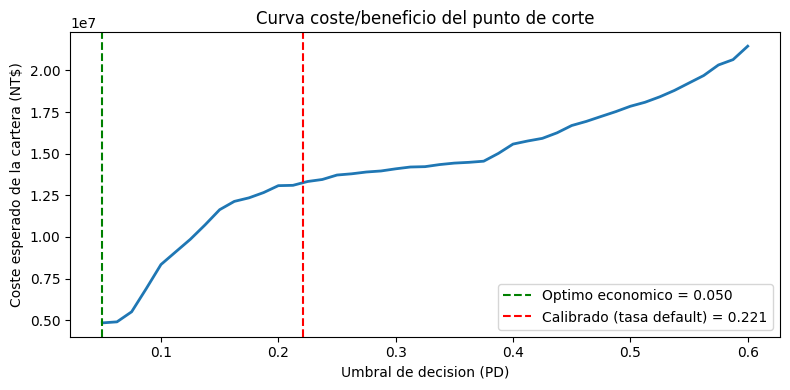

Umbral optimo (coste minimo): 0.050  -> coste NT$ 4,845,935
Umbral calibrado (0.221):        coste NT$ 13,330,961
PD minima observada en test:  0.0376


In [29]:
# Coste esperado de la cartera en funcion del umbral de decision
#   Falso negativo: no detectar a un moroso  -> perdida = LGD x EAD
#   Falso positivo: marcar a un cliente sano -> 2% del saldo (supuesto)

LGD_CB = LGD_DEFECTO   # mismo LGD que IFRS 9 (config_riesgo)
COSTE_FP_PCT = 0.02

pd_cb = Y_test_pred
y_cb = np.asarray(Y_test)
ead_cb = df_test['BILL_AMT1'].clip(lower=0).values


def coste_cartera(umbral, coste_fp_pct=COSTE_FP_PCT):
    """Coste esperado de la cartera para un umbral de decision dado."""
    pred = (pd_cb >= umbral).astype(int)
    fn = (pred == 0) & (y_cb == 1)
    fp = (pred == 1) & (y_cb == 0)
    return (LGD_CB * ead_cb[fn]).sum() + (coste_fp_pct * ead_cb[fp]).sum()


umbrales = np.linspace(0.05, 0.60, 45)
costes = np.array([coste_cartera(u) for u in umbrales])

u_opt = umbrales[costes.argmin()]
u_calibr = df_train['y'].mean()
coste_cal = costes[np.abs(umbrales - u_calibr).argmin()]

plt.figure(figsize=(8, 4))
plt.plot(umbrales, costes, lw=2)
plt.axvline(u_opt,    color='green', ls='--', label=f'Optimo economico = {u_opt:.3f}')
plt.axvline(u_calibr, color='red',   ls='--', label=f'Calibrado (tasa default) = {u_calibr:.3f}')
plt.xlabel('Umbral de decision (PD)')
plt.ylabel('Coste esperado de la cartera (NT$)')
plt.title('Curva coste/beneficio del punto de corte')
plt.legend(); plt.tight_layout(); plt.show()

print(f'Umbral optimo (coste minimo): {u_opt:.3f}  -> coste NT$ {costes.min():,.0f}')
print(f'Umbral calibrado ({u_calibr:.3f}):        coste NT$ {coste_cal:,.0f}')
print(f'PD minima observada en test:  {pd_cb.min():.4f}')

### Por qué ese óptimo no es utilizable

El mínimo cae en **0,050**, que es el primer valor del rango explorado y además queda
**por debajo de la PD mínima observada en la cartera (0,051)**. Aplicarlo marcaría en
riesgo a la práctica totalidad de los clientes: no es un umbral de gestión.

Se trata de un **óptimo de frontera**, no económico. Dos señales lo delatan:

1. **Coincide con el borde de la rejilla.** El barrido empezaba justo ahí, de modo que
   no sabemos si el coste seguiría bajando por debajo: el mínimo puede ser un artefacto
   de haber truncado la búsqueda.
2. **La función de coste es monótona creciente** en todo el rango. Con un falso negativo
   que cuesta 0,45 × EAD frente a un falso positivo de 0,02 × EAD, el ratio es de 22,5 a 1:
   detectar morosos domina por completo y "minimizar el coste" degenera en marcar a todos.

De aquí se siguen dos preguntas que la celda anterior no puede responder, y que resuelve
la siguiente:

- **¿Existe realmente un óptimo interior?** Hay que ampliar el barrido por debajo de la
  PD mínima para comprobar si el mínimo se desplaza o si el coste sigue cayendo.
- **¿Cuánto depende el resultado del supuesto de coste?** El 2 % del saldo es una
  hipótesis, no un dato. Conviene ver a partir de qué coste del falso positivo el óptimo
  deja de ser degenerado.

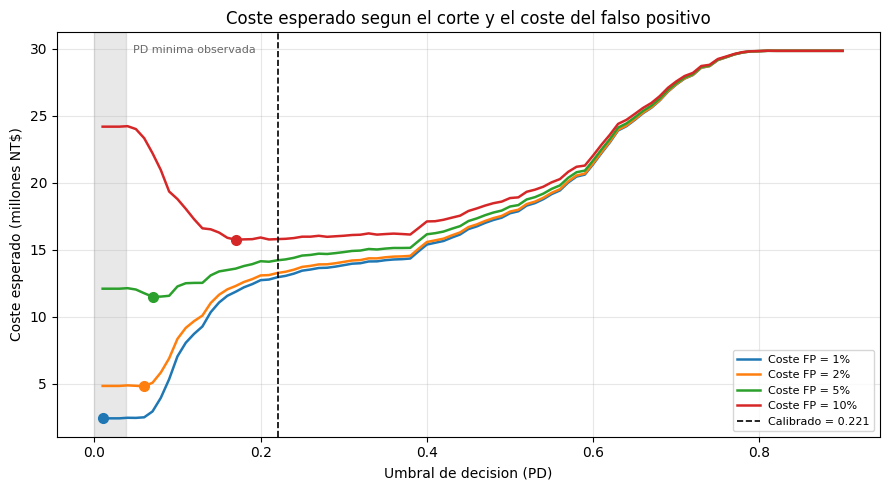

coste_FP  ratio_FN/FP  umbral_optimo coste_optimo  degenerado
      1%         45.0           0.01    2,418,067        True
      2%         22.5           0.06    4,810,221       False
      5%          9.0           0.07   11,496,403       False
     10%          4.5           0.17   15,746,550       False

PD minima observada: 0.0376  |  Corte calibrado: 0.221

Escenarios con optimo degenerado: 1 de 4.
El optimo deja de ser degenerado a partir de un coste de falso positivo del 2% del saldo (ratio 22.5), donde se situa en 0.060.

Este barrido sobre el test solo sirve de contraste. El corte que se despliega
se fija en la celda siguiente con la regla de Bayes, sin ajustar nada sobre el test.


In [30]:
# Rejilla ampliada + sensibilidad al coste del falso positivo

pd_min = pd_cb.min()
umbrales_amp = np.linspace(0.01, 0.90, 90)   # arranca por debajo de la PD minima
ESCENARIOS_FP = [0.01, 0.02, 0.05, 0.10]      # % del saldo

filas, curvas = [], {}
for c_fp in ESCENARIOS_FP:
    c = np.array([coste_cartera(u, c_fp) for u in umbrales_amp])
    curvas[c_fp] = c
    uo = umbrales_amp[c.argmin()]
    filas.append({
        'coste_FP':      f'{c_fp:.0%}',
        'ratio_FN/FP':   round(LGD_CB / c_fp, 1),
        'umbral_optimo': round(float(uo), 3),
        'coste_optimo':  f'{c.min():,.0f}',
        'degenerado':    bool(uo <= pd_min),   # marcaria a toda la cartera
    })

tabla_coste = pd.DataFrame(filas)

plt.figure(figsize=(9, 5))
for c_fp in ESCENARIOS_FP:
    c = curvas[c_fp]
    linea, = plt.plot(umbrales_amp, c / 1e6, lw=1.8, label=f'Coste FP = {c_fp:.0%}')
    plt.plot(umbrales_amp[c.argmin()], c.min() / 1e6, 'o', ms=7, color=linea.get_color())

plt.axvline(u_calibr, color='black', ls='--', lw=1.2, label=f'Calibrado = {u_calibr:.3f}')
plt.axvspan(0, pd_min, color='grey', alpha=0.18)
plt.text(pd_min, plt.ylim()[1]*0.97, '  PD minima observada', va='top', fontsize=8, color='dimgrey')
plt.xlabel('Umbral de decision (PD)')
plt.ylabel('Coste esperado (millones NT$)')
plt.title('Coste esperado segun el corte y el coste del falso positivo')
plt.legend(fontsize=8); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

print(tabla_coste.to_string(index=False))
print(f'\nPD minima observada: {pd_min:.4f}  |  Corte calibrado: {u_calibr:.3f}')

n_deg = int(tabla_coste['degenerado'].sum())
print(f'\nEscenarios con optimo degenerado: {n_deg} de {len(ESCENARIOS_FP)}.')
no_deg = tabla_coste[~tabla_coste['degenerado']]
if len(no_deg):
    f0 = no_deg.iloc[0]
    print(f"El optimo deja de ser degenerado a partir de un coste de falso positivo del "
          f"{f0['coste_FP']} del saldo (ratio {f0['ratio_FN/FP']}), donde se situa en "
          f"{f0['umbral_optimo']:.3f}.")
else:
    print('En ningun escenario aparece un optimo interior: minimizar el coste esperado')
    print('equivale siempre a marcar toda la cartera bajo estos supuestos.')

print('\nEste barrido sobre el test solo sirve de contraste. El corte que se despliega')
print('se fija en la celda siguiente con la regla de Bayes, sin ajustar nada sobre el test.')

## PUNTO DE CORTE SENSIBLE AL COSTE (regla de decisión de Bayes)

Los dos errores no cuestan lo mismo:

- **Falso negativo**: se trata como sano a un titular que acaba en impago. Se pierde el
  principal no recuperado, **LGD × EAD**.
- **Falso positivo**: se trata como riesgo a un buen pagador. Se pierde el coste de gestión
  y, sobre todo, el **margen de intereses** que se deja de ganar al recortarle el límite.

Con una PD **calibrada**, el corte que minimiza el coste esperado tiene fórmula cerrada. No
marcar al titular cuesta, en esperanza, PD × LGD × EAD; marcarlo cuesta (1 − PD) × c × EAD,
siendo *c* el coste del falso positivo como proporción del saldo. Conviene marcarlo cuando lo
primero supera a lo segundo:

$$\text{PD} > \frac{c}{\text{LGD} + c}$$

El EAD se cancela, de modo que el corte no depende del saldo. Y como sale de una fórmula y no
de una búsqueda sobre los datos, **no introduce ninguna fuga**: el test solo se usa para medir.
La regla solo es válida si la probabilidad está calibrada, que es otra razón para mantener el
scorecard frente a un modelo que no lo está.

Si *c* recoge solo la gestión, la asimetría es tan grande que el corte cae por debajo de la PD
mínima de la cartera y la regla marca a todos los titulares: es el óptimo degenerado del
apartado anterior. Por eso *c* incluye el margen perdido. Ese margen es un **supuesto**: en
una entidad real saldría del rendimiento efectivo de la cartera.

In [31]:
# COSTE_GESTION_FP, MARGEN_PERDIDO_FP y COSTE_FP vienen de config_riesgo.py, para que el
# notebook de equidad evalue exactamente el mismo corte
UMBRAL_DEGENERADO = 0.90   # un corte que marca a mas del 90 % de la cartera no es operable


def umbral_bayes(coste_fp, lgd=LGD_CB):
    """Corte de minimo coste esperado con una PD calibrada: c / (LGD + c)."""
    return coste_fp / (lgd + coste_fp)


escenarios_corte = []
for c in (0.02, 0.05, 0.10, 0.15):
    u = umbral_bayes(c)
    marcados = float((pd_cb >= u).mean())
    escenarios_corte.append({
        'coste FP (% saldo)': f'{c:.0%}',
        'ratio coste FN/FP':  round(LGD_CB / c, 1),
        'corte':              round(u, 4),
        '% cartera marcada':  round(100 * marcados, 1),
        'operable':           'no: marca casi toda la cartera' if marcados >= UMBRAL_DEGENERADO else 'sí',
    })
print("=== Corte de Bayes segun el coste del falso positivo ===")
display(pd.DataFrame(escenarios_corte))

umbral_coste = umbral_bayes(COSTE_FP)
print(f"Coste del falso positivo: gestion {COSTE_GESTION_FP:.0%} + margen perdido "
      f"{MARGEN_PERDIDO_FP:.0%} = {COSTE_FP:.0%} del saldo")
print(f"Corte sensible al coste: {umbral_coste:.4f}  |  corte neutro: {u_calibr:.4f}")

=== Corte de Bayes segun el coste del falso positivo ===


,coste FP (% saldo),ratio coste FN/FP,corte,% cartera marcada,operable
0,2%,22.5,0.0426,99.7,no: marca casi toda la cartera
1,5%,9.0,0.1000,71.3,sí
2,10%,4.5,0.1818,33.5,sí
3,15%,3.0,0.2500,25.4,sí


Coste del falso positivo: gestion 2% + margen perdido 8% = 10% del saldo
Corte sensible al coste: 0.1818  |  corte neutro: 0.2212


### Matrices de confusión: corte neutro frente a corte sensible al coste

Las dos matrices se calculan sobre la misma muestra de test y con el mismo modelo: lo único
que cambia es el corte. Bajar el corte desplaza titulares de la columna *marcado sano* a la
columna *marcado riesgo*. Se detectan más impagos (menos falsos negativos) a cambio de marcar
a más buenos pagadores (más falsos positivos). La tercera matriz muestra ese desplazamiento
directamente, casilla a casilla, y la tabla de costes indica si el intercambio compensa con los
supuestos adoptados.

Conviene no elegir el corte mirando qué coste sale menor en el test: eso volvería a ajustar
una decisión sobre la muestra de evaluación. El corte se fija con la regla de Bayes y el test
solo dice cuánto cuesta. Si la diferencia de coste es pequeña, la curva es plana en esa zona y
la elección es de apetito de riesgo: detectar más impagos o generar menos falsas alarmas.

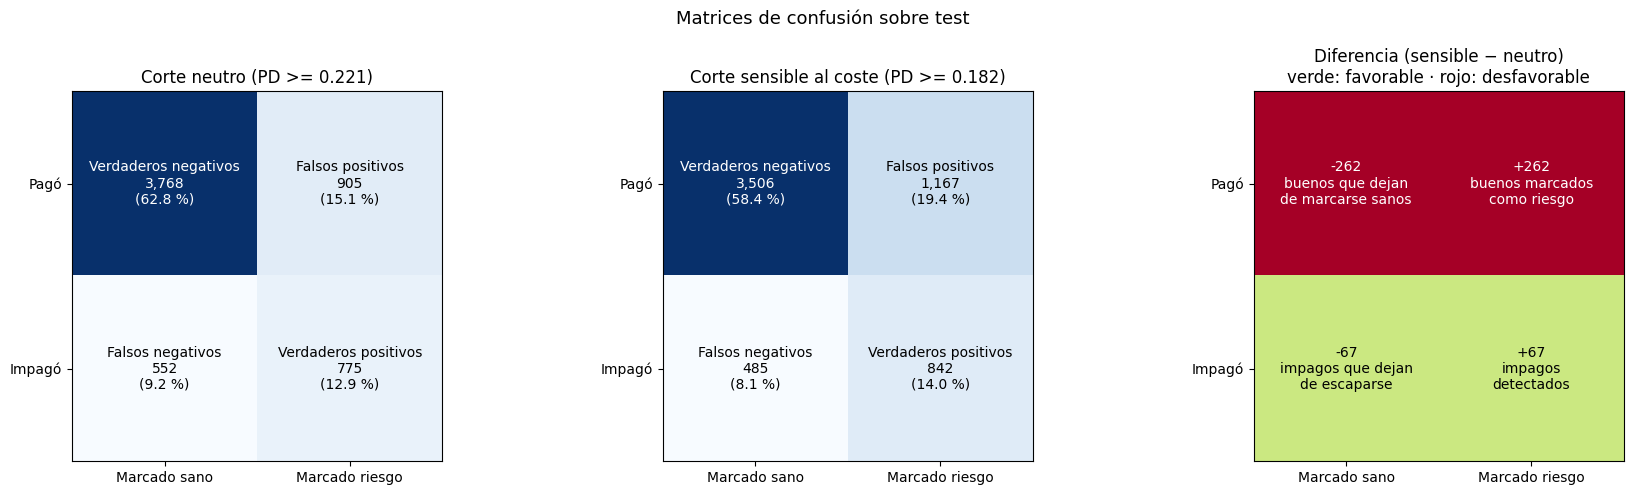

,Corte neutro,Corte sensible al coste,Diferencia
,,,
Punto de corte,0.2212,0.1818,-0.0394
Verdaderos positivos,775,842,67
Falsos positivos,905,"1,167",262
Falsos negativos,552,485,-67
Verdaderos negativos,"3,768","3,506",-262
Impagos detectados (recall),58.4%,63.5%,+5.0 pp
Acierto al marcar (precision),46.1%,41.9%,-4.2 pp
Cartera marcada como riesgo,28.0%,33.5%,+5.5 pp
Coste de falsos negativos (NT$),"12,625,277","11,814,755","-810,522"


Impagos que deja de pasar por alto el corte sensible: 67
Buenos pagadores adicionales marcados como riesgo:     262
Variacion del coste total frente al corte neutro:      -49,858 NT$ (-0.3%)

La diferencia de coste es inferior al 2 %: en esta zona la curva de coste es
plana, y elegir entre los dos cortes es una decision de apetito de riesgo
(detectar mas impagos o generar menos falsas alarmas), no de coste.


In [32]:
from sklearn.metrics import confusion_matrix


def evaluar_corte(umbral, nombre):
    """Matriz de confusion y coste de un corte sobre el test."""
    pred = (pd_cb >= umbral).astype(int)
    vn, fp, fn, vp = confusion_matrix(y_cb, pred, labels=[0, 1]).ravel()
    coste_fn = float((LGD_CB * ead_cb[(pred == 0) & (y_cb == 1)]).sum())
    coste_fp = float((COSTE_FP * ead_cb[(pred == 1) & (y_cb == 0)]).sum())
    return {
        'nombre': nombre, 'umbral': umbral, 'pred': pred,
        'VP': int(vp), 'FP': int(fp), 'FN': int(fn), 'VN': int(vn),
        'recall': vp / (vp + fn), 'precision': vp / (vp + fp) if vp + fp else 0.0,
        'marcados': (vp + fp) / len(y_cb),
        'coste_fn': coste_fn, 'coste_fp': coste_fp, 'coste_total': coste_fn + coste_fp,
    }


neutro = evaluar_corte(u_calibr, 'Corte neutro')
sensible = evaluar_corte(umbral_coste, 'Corte sensible al coste')

fig, ejes = plt.subplots(1, 3, figsize=(18, 5))
for eje, r in zip(ejes[:2], (neutro, sensible)):
    m = confusion_matrix(y_cb, r['pred'], labels=[0, 1])
    eje.imshow(m, cmap='Blues')
    rotulos = [['Verdaderos negativos', 'Falsos positivos'],
               ['Falsos negativos', 'Verdaderos positivos']]
    for i in range(2):
        for j in range(2):
            eje.text(j, i, f"{rotulos[i][j]}\n{m[i, j]:,}\n({100 * m[i, j] / m.sum():.1f} %)",
                     ha='center', va='center', fontsize=10,
                     color='white' if m[i, j] > m.max() / 2 else 'black')
    eje.set_xticks([0, 1]); eje.set_xticklabels(['Marcado sano', 'Marcado riesgo'])
    eje.set_yticks([0, 1]); eje.set_yticklabels(['Pagó', 'Impagó'])
    eje.set_title(f"{r['nombre']} (PD >= {r['umbral']:.3f})")

# Tercera matriz: cuantos titulares cambian de casilla al pasar al corte sensible
m_dif = (confusion_matrix(y_cb, sensible['pred'], labels=[0, 1])
         - confusion_matrix(y_cb, neutro['pred'], labels=[0, 1]))
tope = max(abs(m_dif).max(), 1)
# Verde = cambio favorable, rojo = desfavorable
favorable = np.array([[1, -1], [-1, 1]])
ejes[2].imshow(m_dif * favorable, cmap='RdYlGn', vmin=-tope, vmax=tope)
lectura = [['buenos que dejan\nde marcarse sanos', 'buenos marcados\ncomo riesgo'],
           ['impagos que dejan\nde escaparse', 'impagos\ndetectados']]
for i in range(2):
    for j in range(2):
        ejes[2].text(j, i, f"{m_dif[i, j]:+,}\n{lectura[i][j]}", ha='center', va='center',
                     fontsize=10, color='white' if abs(m_dif[i, j]) > 0.6 * tope else 'black')
ejes[2].set_xticks([0, 1]); ejes[2].set_xticklabels(['Marcado sano', 'Marcado riesgo'])
ejes[2].set_yticks([0, 1]); ejes[2].set_yticklabels(['Pagó', 'Impagó'])
ejes[2].set_title('Diferencia (sensible − neutro)\nverde: favorable · rojo: desfavorable')
plt.suptitle('Matrices de confusión sobre test', fontsize=13)
plt.tight_layout(); plt.show()

filas = [
    ('Punto de corte',                     'umbral',      '{:.4f}'),
    ('Verdaderos positivos',               'VP',          '{:,}'),
    ('Falsos positivos',                   'FP',          '{:,}'),
    ('Falsos negativos',                   'FN',          '{:,}'),
    ('Verdaderos negativos',               'VN',          '{:,}'),
    ('Impagos detectados (recall)',        'recall',      '{:.1%}'),
    ('Acierto al marcar (precision)',      'precision',   '{:.1%}'),
    ('Cartera marcada como riesgo',        'marcados',    '{:.1%}'),
    ('Coste de falsos negativos (NT$)',    'coste_fn',    '{:,.0f}'),
    ('Coste de falsos positivos (NT$)',    'coste_fp',    '{:,.0f}'),
    ('Coste total (NT$)',                  'coste_total', '{:,.0f}'),
]
tabla_cortes = pd.DataFrame(
    [[etiqueta, fmt.format(neutro[k]), fmt.format(sensible[k]),
      fmt.format(sensible[k] - neutro[k]) if k not in ('recall', 'precision', 'marcados')
      else f"{100 * (sensible[k] - neutro[k]):+.1f} pp"]
     for etiqueta, k, fmt in filas],
    columns=['', neutro['nombre'], sensible['nombre'], 'Diferencia']).set_index('')
display(tabla_cortes)

variacion = sensible['coste_total'] - neutro['coste_total']
print(f"Impagos que deja de pasar por alto el corte sensible: {neutro['FN'] - sensible['FN']:,}")
print(f"Buenos pagadores adicionales marcados como riesgo:     {sensible['FP'] - neutro['FP']:,}")
print(f"Variacion del coste total frente al corte neutro:      {variacion:+,.0f} NT$ "
      f"({variacion / neutro['coste_total']:+.1%})")
if abs(variacion) / neutro['coste_total'] < 0.02:
    print("\nLa diferencia de coste es inferior al 2 %: en esta zona la curva de coste es")
    print("plana, y elegir entre los dos cortes es una decision de apetito de riesgo")
    print("(detectar mas impagos o generar menos falsas alarmas), no de coste.")

In [33]:
# CORTE QUE SE DESPLIEGA (se guarda en el config para la API, los agentes y Tableau).
# Si el corte de Bayes marcara casi toda la cartera, se mantiene el neutro.
CRITERIO_CORTE = 'coste'          # 'coste' o 'neutro'

if CRITERIO_CORTE == 'coste' and sensible['marcados'] < UMBRAL_DEGENERADO:
    Prob_Corte = float(umbral_coste)
    print(f"Corte desplegado: sensible al coste, {Prob_Corte:.4f}")
else:
    Prob_Corte = float(u_calibr)
    if CRITERIO_CORTE == 'coste':
        print("AVISO: el corte de Bayes marcaria a mas del "
              f"{UMBRAL_DEGENERADO:.0%} de la cartera; se mantiene el neutro.")
    print(f"Corte desplegado: neutro, {Prob_Corte:.4f}")

Corte desplegado: sensible al coste, 0.1818


## DE PROBABILIDADES A PUNTUACIONES (SCORES)

In [34]:
score = tarjeta.score(X)
print(f"\nScore mín: {score.min():.0f} | máx: {score.max():.0f} | media: {score.mean():.0f}")


Score mín: 637 | máx: 779 | media: 728


## MODELO CHALLENGER SIN RESTRICCIONES - XGBoost + MLflow

Siguiendo el enfoque champion-challenger, se contrasta el scorecard con un modelo sin
ninguna restricción de interpretabilidad: XGBoost sobre todas las variables candidatas en
crudo, incluidas las que el Information Value descartó y las seis derivadas, con los
hiperparámetros optimizados por búsqueda aleatoria y validación cruzada sobre el
entrenamiento.

Los dos modelos disponen de la misma información, incluidas las variables derivadas: la
diferencia entre ellos mide lo que cuesta la interpretabilidad, no la falta de información.

In [35]:
# XGBOOST SIN RESTRICCIONES: todas las variables y busqueda de hiperparametros
# (solo sobre train)
from sklearn.model_selection import RandomizedSearchCV

N_ITER_BUSQUEDA = 30
espacio_busqueda = {
    'n_estimators':     [200, 300, 400, 600, 800],
    'max_depth':        [2, 3, 4, 5, 6],
    'learning_rate':    [0.01, 0.02, 0.05, 0.1],
    'subsample':        [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'min_child_weight': [1, 5, 10, 20],
    'gamma':            [0, 0.1, 0.5, 1.0],
    'reg_lambda':       [1, 5, 10, 50],
}
peso_positivos = (Y == 0).sum() / (Y == 1).sum()

X_train_raw = df_train[list_variables]
X_test_raw = df_test[list_variables]

busqueda_raw = RandomizedSearchCV(
    estimator=xgb.XGBClassifier(objective='binary:logistic', eval_metric='logloss',
                                scale_pos_weight=peso_positivos, tree_method='hist',
                                random_state=RANDOM_SEED, n_jobs=1),
    param_distributions=espacio_busqueda, n_iter=N_ITER_BUSQUEDA, scoring='roc_auc',
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED),
    random_state=RANDOM_SEED, n_jobs=-1, refit=True, verbose=0)

print(f"Buscando sobre {X_train_raw.shape[1]} variables "
      f"({N_ITER_BUSQUEDA} combinaciones x 5 particiones)...")
busqueda_raw.fit(X_train_raw, Y)
modelo_xgb_raw = busqueda_raw.best_estimator_
pred_test_raw  = modelo_xgb_raw.predict_proba(X_test_raw)[:, 1]
auc_test_raw   = roc_auc_score(Y_test, pred_test_raw)
print(f"AUC validacion cruzada: {busqueda_raw.best_score_:.4f} | AUC test: {auc_test_raw:.4f}")

# Registro de los tres modelos en MLflow
mlflow.set_experiment('credit_risk_taiwan')
with mlflow.start_run(run_name='scorecard_champion'):
    mlflow.log_param('n_variables_candidatas', len(list_variables))
    mlflow.log_param('variables_derivadas', ', '.join(VARIABLES_DERIVADAS))
    mlflow.log_metric('auc_test', auc_test_sc)
    mlflow.sklearn.log_model(tarjeta.estimator_, 'model')
with mlflow.start_run(run_name='xgboost_sin_restricciones'):
    mlflow.log_params(busqueda_raw.best_params_)
    mlflow.log_param('n_variables', X_train_raw.shape[1])
    mlflow.log_metric('auc_cv', busqueda_raw.best_score_)
    mlflow.log_metric('auc_test', auc_test_raw)
    mlflow.xgboost.log_model(modelo_xgb_raw, 'model')

Buscando sobre 28 variables (30 combinaciones x 5 particiones)...
AUC validacion cruzada: 0.7874 | AUC test: 0.7858


2026/10/21 15:12:32 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/21 15:12:32 INFO mlflow.store.db.utils: Updating database tables
2026/10/21 15:12:36 INFO mlflow.tracking.fluent: Experiment with name 'credit_risk_taiwan' does not exist. Creating a new experiment.
2026/10/21 15:12:36 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/21 15:12:46 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


## Registro de experimentos en MLflow

Se recuperan los runs registrados y se muestran en una tabla comparativa.

Al final hay una celda opcional por si se prefiere la interfaz web de MLflow.

In [36]:

# Leemos los runs directamente del backend local (./mlruns).
runs = mlflow.search_runs(experiment_names=["credit_risk_taiwan"])

if runs.empty:
    print("No hay runs registrados. Ejecuta antes la celda de entrenamiento con MLflow.")
else:
    # Nos quedamos con las columnas relevantes y les damos nombres legibles
    cols = {
        "tags.mlflow.runName": "Modelo",
        "metrics.auc_test":    "AUC test",
        "params.n_estimators": "n_estimators",
        "params.max_depth":    "max_depth",
        "start_time":          "Fecha",
    }
    presentes = {k: v for k, v in cols.items() if k in runs.columns}
    tabla = runs[list(presentes)].rename(columns=presentes)

    if "AUC test" in tabla.columns:
        tabla["AUC test"] = tabla["AUC test"].astype(float).round(4)
        # Gini = 2*AUC - 1, metrica habitual en riesgo de credito
        tabla["Gini"] = (2 * tabla["AUC test"] - 1).round(4)
    if "Fecha" in tabla.columns:
        tabla["Fecha"] = pd.to_datetime(tabla["Fecha"]).dt.strftime("%Y-%m-%d %H:%M")

    tabla = tabla.sort_values("AUC test", ascending=False).reset_index(drop=True)

    print("Experimento: credit_risk_taiwan")
    print(f"Runs registrados: {len(tabla)}\n")
    display(tabla)

Experimento: credit_risk_taiwan
Runs registrados: 2



,Modelo,AUC test,n_estimators,max_depth,Fecha,Gini
0,xgboost_sin_restricciones,0.7858,300,5,2026-10-21 15:12,0.5716
1,scorecard_champion,0.7594,None,None,2026-10-21 15:12,0.5188


## COMPARATIVA: SCORECARD FRENTE AL CHALLENGER

La diferencia de AUC entre dos modelos medida sobre la misma muestra arrastra error
muestral. Por eso se acompaña de un **intervalo de confianza bootstrap emparejado**: en cada
réplica se remuestrean las mismas filas para los dos modelos, de modo que el intervalo mide
la diferencia y no la suma de dos incertidumbres independientes. Si el intervalo contiene el
cero, la diferencia no es concluyente.

,Modelo,Representación,AUC test,Gini,Brier,Δ AUC vs champion (IC 95 %),Interpretabilidad
0,Scorecard (champion),"WOE, variables con IV >= 0,02",0.7594,0.5188,0.1390,-,Tabla de puntos
1,XGBoost sin restricciones,"Crudas + derivadas, todas",0.7858,0.5715,0.1765,"+0.0263 [+0.0197, +0.0327] (sí)",Con SHAP


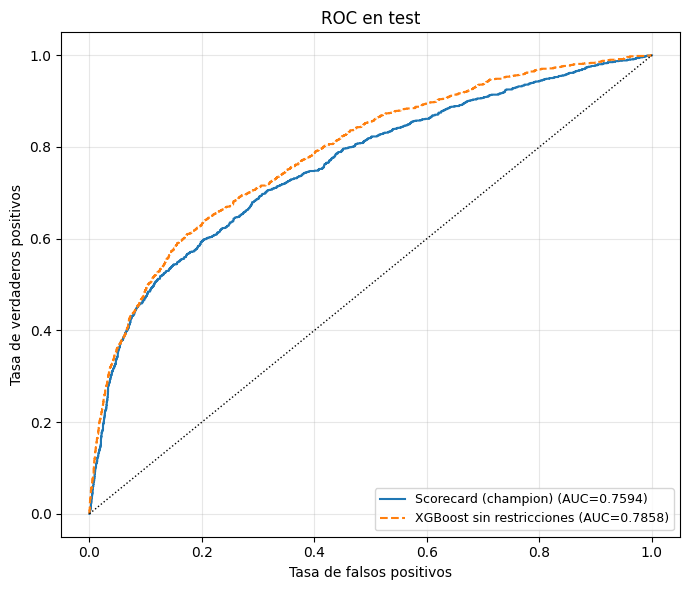

Calibracion (Brier, menor es mejor): scorecard 0.1390 | XGBoost 0.1765
PD media predicha: scorecard 0.2195 | XGBoost 0.4162 | tasa observada 0.2212
El XGBoost usa scale_pos_weight, que reequilibra la clase positiva y descalibra su
probabilidad: ordena bien, pero su salida no es una PD utilizable para provisionar
sin recalibrarla, paso que el scorecard no necesita.


In [37]:
from sklearn.metrics import brier_score_loss


def ic_diferencia_auc(y_real, pred_base, pred_alt, n_boot=1000, seed=RANDOM_SEED):
    """IC bootstrap emparejado de la diferencia de AUC (alternativo - base)."""
    rng = np.random.default_rng(seed)
    y, pb, pa = np.asarray(y_real), np.asarray(pred_base), np.asarray(pred_alt)
    dif = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y), len(y))
        if len(np.unique(y[idx])) < 2:
            continue
        dif.append(roc_auc_score(y[idx], pa[idx]) - roc_auc_score(y[idx], pb[idx]))
    dif = np.array(dif)
    return dif.mean(), *np.percentile(dif, [2.5, 97.5])


modelos = [
    ('Scorecard (champion)',      Y_test_pred,   'WOE, variables con IV >= 0,02', 'Tabla de puntos'),
    ('XGBoost sin restricciones', pred_test_raw, 'Crudas + derivadas, todas',     'Con SHAP'),
]
filas_c = []
for nombre, pred, representacion, interpretable in modelos:
    auc_m = roc_auc_score(Y_test, pred)
    if 'champion' in nombre:
        delta = '-'
    else:
        d_m, d_b, d_a = ic_diferencia_auc(Y_test, Y_test_pred, pred)
        delta = (f"{d_m:+.4f} [{d_b:+.4f}, {d_a:+.4f}] "
                 f"({'no' if d_b <= 0 <= d_a else 'sí'})")
    filas_c.append({'Modelo': nombre, 'Representación': representacion,
                    'AUC test': round(auc_m, 4), 'Gini': round(2 * auc_m - 1, 4),
                    'Brier': round(brier_score_loss(Y_test, pred), 4),
                    'Δ AUC vs champion (IC 95 %)': delta,
                    'Interpretabilidad': interpretable})
display(pd.DataFrame(filas_c))

plt.figure(figsize=(7, 6))
for (nombre, pred, *_), estilo in zip(modelos, ['-', '--']):
    fpr_m, tpr_m, _ = roc_curve(Y_test, pred)
    plt.plot(fpr_m, tpr_m, estilo, label=f'{nombre} (AUC={roc_auc_score(Y_test, pred):.4f})')
plt.plot([0, 1], [0, 1], 'k:', lw=1)
plt.xlabel('Tasa de falsos positivos'); plt.ylabel('Tasa de verdaderos positivos')
plt.title('ROC en test'); plt.legend(loc='lower right', fontsize=9)
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

brier_sc = brier_score_loss(Y_test, Y_test_pred)
brier_xgb = brier_score_loss(Y_test, pred_test_raw)
print(f"Calibracion (Brier, menor es mejor): scorecard {brier_sc:.4f} | XGBoost {brier_xgb:.4f}")
print(f"PD media predicha: scorecard {Y_test_pred.mean():.4f} | XGBoost {pred_test_raw.mean():.4f} "
      f"| tasa observada {np.mean(Y_test):.4f}")
if brier_xgb > brier_sc:
    print("El XGBoost usa scale_pos_weight, que reequilibra la clase positiva y descalibra su")
    print("probabilidad: ordena bien, pero su salida no es una PD utilizable para provisionar")
    print("sin recalibrarla, paso que el scorecard no necesita.")
else:
    print("En esta ejecucion la calibracion del XGBoost no es peor que la del scorecard:")
    print("el argumento de calibracion no aplica y la eleccion descansa en la auditabilidad.")

### Lectura de la comparación

Como los dos modelos parten de la misma información, la diferencia de AUC mide lo que cuesta
la interpretabilidad: la capacidad de ordenación que se renuncia al usar una tabla de puntos
en lugar de un modelo sin restricciones. Se lee con su intervalo emparejado: si contiene el
cero, la diferencia no es concluyente.

El scorecard se mantiene como modelo en producción por dos razones que no dependen de la
magnitud de esa ventaja: su probabilidad está calibrada, como confirma su Brier score, y una
tabla de puntos se audita tramo a tramo sin necesidad de reconstruir después por qué decidió
el modelo.

## EXPLICABILIDAD DEL CHALLENGER CON SHAP

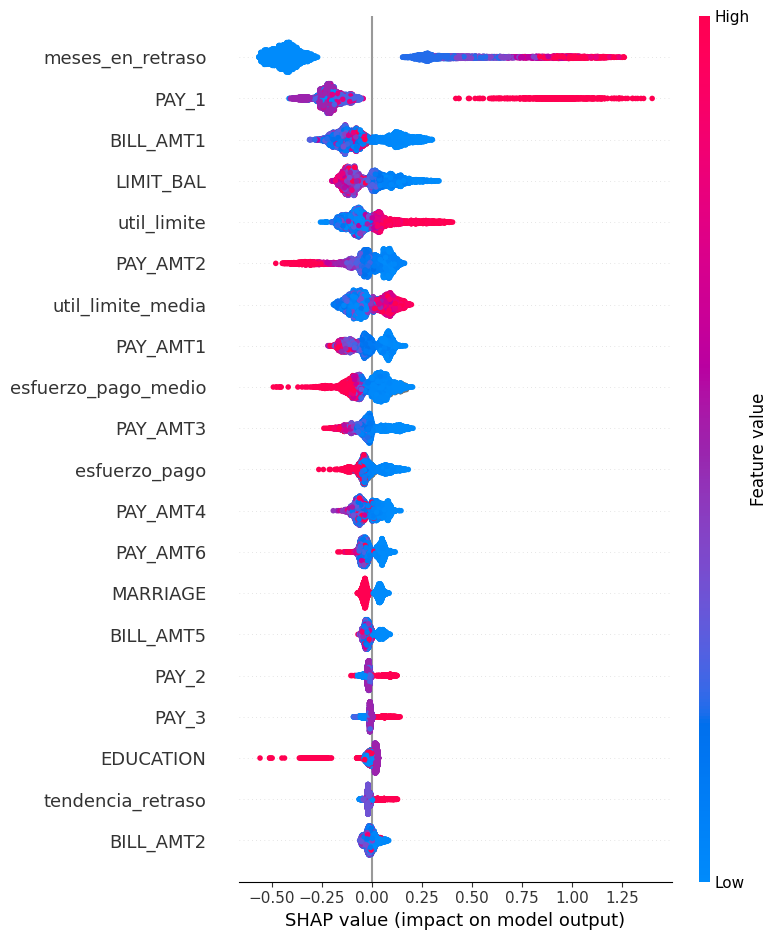

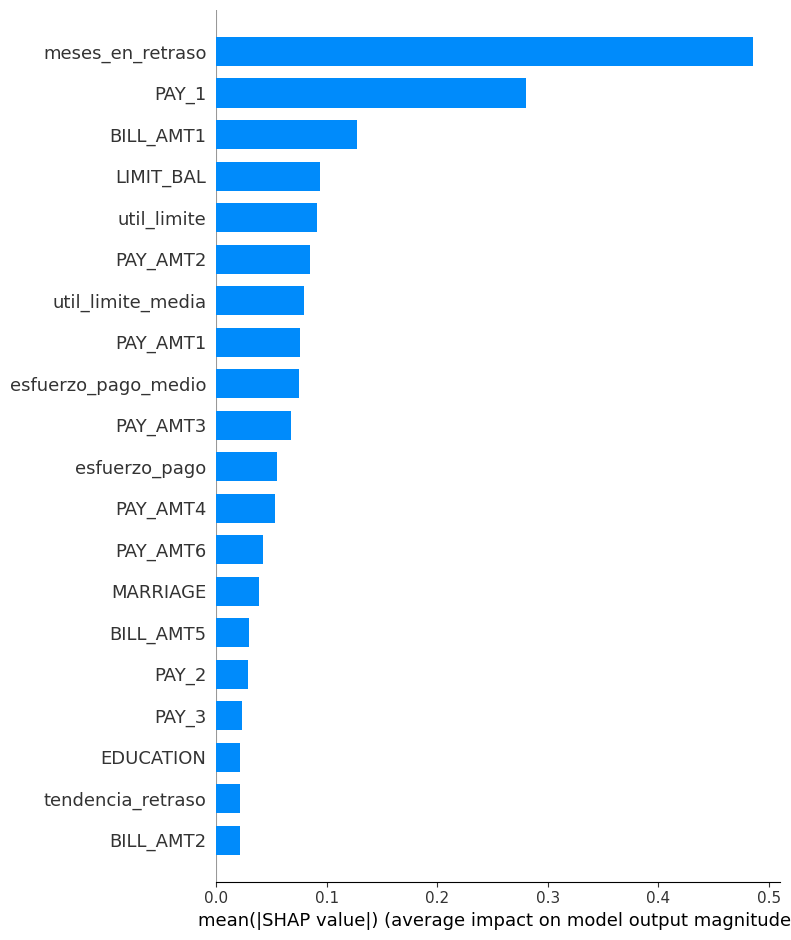

In [38]:
explainer = shap.TreeExplainer(modelo_xgb_raw)
shap_values = explainer.shap_values(X_test_raw)

shap.summary_plot(shap_values, X_test_raw, show=True)
shap.summary_plot(shap_values, X_test_raw, plot_type='bar', show=True)

## IFRS 9 - ESTRUCTURA TEMPORAL DE LA PD (cadena de Markov)

La PD del scorecard estima la probabilidad de **retraso en el mes siguiente**. La NIIF 9 pide
otra cosa: la probabilidad de **default** a 12 meses en el Stage 1 y a toda la vida de la
operación en los Stages 2 y 3. Se construye con una cadena de Markov sobre tres estados de
morosidad, con la definición de default del artículo 178 del CRR:

- **Al corriente**: estado de pago cero o negativo.
- **De 30 a 89 días**: uno o dos meses de retraso.
- **Default**: 90 días o más. Es absorbente, porque la PD mide la primera entrada en default.

Las transiciones se cuentan entre meses consecutivos de **abril a agosto**, solo sobre
entrenamiento, y se excluye septiembre por su codificación distinta. Elevando la matriz
mensual al horizonte se obtiene la PD acumulada.

La PD de default se asigna **por estado de morosidad**: es una evaluación colectiva por
tramo de retraso, la habitual en carteras minoristas y admitida por la NIIF 9. Se descartó
escalarla por el riesgo relativo del scorecard dentro de cada estado, porque el scorecard
separa los estados por un factor mucho mayor que la cadena a 36 meses y ese escalado hacía
bajar la PD de vida al empeorar el estado de pago. El scorecard conserva su papel en la
ordenación de la cartera, la decisión y el criterio cuantitativo del Stage 2.

Supuestos: cadena homogénea en el tiempo y sin memoria, estimada con cuatro transiciones, y
vida esperada de 36 meses para una tarjeta, que no tiene vencimiento contractual (la NIIF 9
admite la vida conductual en productos renovables, apartado 5.5.20).

**Nota de lectura:** la PD media a 12 meses puede salir menor que la PD a un mes del
scorecard. No es un error: son sucesos distintos. Un retraso en el mes siguiente es mucho más
frecuente que llegar a 90 días de impago.

In [39]:
# Los parametros se estiman sobre los valores brutos del entrenamiento.
bruto_train = df.loc[df_train.index]
bruto_test = df.loc[df_test.index]

PARES_TRANSICION = [(6, 5), (5, 4), (4, 3), (3, 2)]   # abr->may ... jul->ago
conteo = np.zeros((3, 3))
for origen, destino in PARES_TRANSICION:
    e_o = estado_mora(bruto_train[f'PAY_{origen}'])
    e_d = estado_mora(bruto_train[f'PAY_{destino}'])
    for i in (0, 1):
        for j in (0, 1, 2):
            conteo[i, j] += np.sum((e_o == i) & (e_d == j))
n_transiciones = int(conteo.sum())
conteo[2] = [0, 0, 1]                                 # default absorbente
matriz_markov = conteo / conteo.sum(axis=1, keepdims=True)

nombres_estado = ['Al corriente', '30-89 días', 'Default 90+']
print(f"Matriz de transicion mensual ({n_transiciones} transiciones de entrenamiento):")
display(pd.DataFrame(matriz_markov, index=nombres_estado, columns=nombres_estado).round(4))

pd_estado_12m = np.linalg.matrix_power(matriz_markov, HORIZONTE_12M)[:, 2]
pd_estado_vida = np.linalg.matrix_power(matriz_markov, VIDA_ESPERADA)[:, 2]
print("PD acumulada segun el estado de partida:")
display(pd.DataFrame({
    '1 mes':                   matriz_markov[:, 2],
    f'{HORIZONTE_12M} meses':  pd_estado_12m,
    f'{VIDA_ESPERADA} meses':  pd_estado_vida,
}, index=nombres_estado).iloc[:2].round(4))

Matriz de transicion mensual (94861 transiciones de entrenamiento):


,Al corriente,30-89 días,Default 90+
Al corriente,0.9509,0.0491,0.0000
30-89 días,0.3019,0.6377,0.0604
Default 90+,0.0000,0.0000,1.0000


PD acumulada segun el estado de partida:


,1 mes,12 meses,36 meses
Al corriente,0.0000,0.0677,0.2188
30-89 días,0.0604,0.2068,0.3356


## IFRS 9 - STAGES CON LOS CRITERIOS DE LA NORMA

La asignación anterior por umbrales de PD clasificaba como deteriorado a cualquier titular
con PD alta. La NIIF 9 define el deterioro por el retraso, no por la probabilidad:

- **Stage 3**: 90 días o más de retraso, presunción de deterioro (apartado B5.5.37).
- **Stage 2**: más de 30 días de retraso, presunción refutable de aumento significativo del
  riesgo (5.5.11), o PD por encima de un criterio cuantitativo. Sin la PD en la fecha de
  concesión no puede medirse el aumento relativo que pide la norma, de modo que se usa un
  umbral absoluto como aproximación.
- **Stage 1**: el resto.

In [40]:
cartera = df_test.copy()
cartera['PD'] = Y_test_pred
cartera['estado_mora'] = estado_mora(bruto_test['PAY_1'])
cartera['Stage'] = asignar_stage(bruto_test['PAY_1'].values, Y_test_pred)

# Comparacion con la asignacion anterior por umbrales de PD (0,15 y 0,35)
stage_anterior = np.where(Y_test_pred < 0.15, 1, np.where(Y_test_pred < 0.35, 2, 3))
comparacion = pd.DataFrame({
    'Por umbrales de PD (anterior)': pd.Series(stage_anterior).value_counts().sort_index(),
    'Por criterios NIIF 9 (actual)': cartera['Stage'].value_counts().sort_index(),
})
comparacion.index.name = 'Stage'
comparacion['% anterior'] = (100 * comparacion.iloc[:, 0] / len(cartera)).round(1)
comparacion['% actual'] = (100 * comparacion.iloc[:, 1] / len(cartera)).round(1)
display(comparacion)
print(f"Criterio cuantitativo de Stage 2: PD > {UMBRAL_SICR_PD}")

,Por umbrales de PD (anterior),Por criterios NIIF 9 (actual),% anterior,% actual
Stage,,,,
1,3360,4598,56.0,76.6
2,1429,1329,23.8,22.2
3,1211,73,20.2,1.2


Criterio cuantitativo de Stage 2: PD > 0.35


## IFRS 9 - EXPOSICIÓN CON FACTOR DE CONVERSIÓN (CCF)

En una tarjeta, la exposición en el momento del default no es solo el saldo dispuesto hoy:
el titular puede seguir disponiendo de su límite libre hasta entrar en default. El factor de
conversión mide qué parte de ese límite libre llega a disponer. Se estima con los titulares
de entrenamiento que entran en default en agosto, comparando su saldo entonces con el de
cuatro meses antes. Se usa agosto y no septiembre por la codificación de PAY_1.

EAD = saldo dispuesto + CCF × límite no dispuesto.

Límites: muestra pequeña y ventana de cuatro meses, cuando lo habitual es de doce.

In [41]:
entra_default = (bruto_train['PAY_2'] >= 3) & (bruto_train['PAY_6'] < 3)
saldo_antes = bruto_train['BILL_AMT6'].clip(lower=0)
saldo_luego = bruto_train['BILL_AMT2'].clip(lower=0)
libre_antes = bruto_train['LIMIT_BAL'] - saldo_antes
validos = entra_default & (libre_antes > 0)
ccf_obs = ((saldo_luego - saldo_antes) / libre_antes).where(validos).clip(0, 1).dropna()
CCF_MEDIO = float(ccf_obs.mean())

print(f"CCF estimado con {len(ccf_obs)} titulares que entran en default en agosto:")
print(f"  media {CCF_MEDIO:.3f} | mediana {ccf_obs.median():.3f} | "
      f"p25 {ccf_obs.quantile(.25):.3f} | p75 {ccf_obs.quantile(.75):.3f}")
print("Distribucion en forma de U, habitual en tarjetas: unos agotan el limite y")
print("otros no lo tocan. Se usa la media como estimacion puntual.")

cartera['EAD_sin_CCF'] = bruto_test['BILL_AMT1'].clip(lower=0).values
cartera['EAD'] = ead_con_ccf(bruto_test['BILL_AMT1'].values,
                             bruto_test['LIMIT_BAL'].values, CCF_MEDIO)
print(f"\nEAD de la cartera de test: {cartera['EAD_sin_CCF'].sum():,.0f} NT$ sin CCF "
      f"-> {cartera['EAD'].sum():,.0f} NT$ con CCF "
      f"({cartera['EAD'].sum() / cartera['EAD_sin_CCF'].sum() - 1:+.0%})")
print(f"Titulares con saldo nulo que pasan a tener exposicion: "
      f"{int(((cartera['EAD_sin_CCF'] == 0) & (cartera['EAD'] > 0)).sum())}")

CCF estimado con 314 titulares que entran en default en agosto:
  media 0.324 | mediana 0.018 | p25 0.000 | p75 0.915
Distribucion en forma de U, habitual en tarjetas: unos agotan el limite y
otros no lo tocan. Se usa la media como estimacion puntual.

EAD de la cartera de test: 311,716,115 NT$ sin CCF -> 544,210,671 NT$ con CCF (+75%)
Titulares con saldo nulo que pasan a tener exposicion: 523


## IFRS 9 - PÉRDIDA ESPERADA POR STAGE

ECL = PD × LGD × EAD, con la PD a 12 meses en el Stage 1 y a toda la vida en los Stages 2 y 3.
En el Stage 3 la PD vale 1, porque el titular ya está en default.

**Sobre la LGD del 45 %:** es un valor convencional de la literatura de credit scoring,
adoptado ante la ausencia de datos de recuperación. No es un parámetro de Basilea: el enfoque
de fundación no existe para la cartera minorista. En tarjetas sin garantía las LGD
observadas suelen ser más altas, de modo que este valor tiende a infraestimar la pérdida.

In [42]:
LGD = LGD_DEFECTO
cartera['PD_12m'] = pd_a_horizonte(cartera['estado_mora'].values, pd_estado_12m)
cartera['PD_vida'] = pd_a_horizonte(cartera['estado_mora'].values, pd_estado_vida)
cartera['ECL'] = calcular_ecl(cartera['PD_12m'].values, cartera['PD_vida'].values,
                              cartera['Stage'].values, LGD, cartera['EAD'].values).round(2)

resumen_ecl = cartera.groupby('Stage').agg(
    clientes=('ECL', 'size'), PD_12m_media=('PD_12m', 'mean'),
    PD_vida_media=('PD_vida', 'mean'), EAD_total=('EAD', 'sum'), ECL_total=('ECL', 'sum'))
resumen_ecl['% del ECL'] = 100 * resumen_ecl['ECL_total'] / resumen_ecl['ECL_total'].sum()
resumen_ecl['cobertura (%)'] = 100 * resumen_ecl['ECL_total'] / resumen_ecl['EAD_total']
print("=== ECL por stage (test) ===")
display(resumen_ecl.round({'PD_12m_media': 4, 'PD_vida_media': 4, 'EAD_total': 0,
                           'ECL_total': 0, '% del ECL': 1, 'cobertura (%)': 2}))
print(f"ECL total: {cartera['ECL'].sum():,.0f} NT$ | "
      f"cobertura global {cartera['ECL'].sum() / cartera['EAD'].sum():.2%}")
print("\n" + AVISO_ECL)

=== ECL por stage (test) ===


,clientes,PD_12m_media,PD_vida_media,EAD_total,ECL_total,% del ECL,cobertura (%)
Stage,,,,,,,
1,4598,0.0677,0.2188,443294664.0,13509725.0,44.7,3.05
2,1329,0.2039,0.3331,95852023.0,14437640.0,47.8,15.06
3,73,1.0000,1.0000,5063984.0,2278793.0,7.5,45.00


ECL total: 30,226,158 NT$ | cobertura global 5.55%

ECL ilustrativo, no apto para provisionar. La PD de default sale de una cadena de Markov por tramo de retraso estimada con cinco meses de historial, la LGD del 45 % es un valor convencional y el CCF se estima con una muestra pequena. Antes de usarlo en real habria que validarlo de forma independiente.


In [43]:
# Sensibilidad a la LGD: el unico parametro que este dataset no permite estimar
print("=== ECL total segun la LGD supuesta ===")
for lgd_s in (0.45, 0.65, 0.85):
    ecl_s = calcular_ecl(cartera['PD_12m'].values, cartera['PD_vida'].values,
                         cartera['Stage'].values, lgd_s, cartera['EAD'].values).sum()
    print(f"  LGD {lgd_s:.0%}: {ecl_s:>16,.0f} NT$")
print("El ECL es lineal en la LGD: el rango muestra cuanto depende la provision de")
print("un parametro que aqui es un supuesto y no una estimacion.")

=== ECL total segun la LGD supuesta ===
  LGD 45%:       30,226,158 NT$
  LGD 65%:       43,660,005 NT$
  LGD 85%:       57,093,853 NT$
El ECL es lineal en la LGD: el rango muestra cuanto depende la provision de
un parametro que aqui es un supuesto y no una estimacion.


## EXPORTACIÓN PARA TABLEAU

Exportamos la cartera evaluada y unos KPIs a un Excel con varias hojas, listo para construir el dashboard de monitorización en Tableau.

In [44]:
# cliente_id (clave para consulta individual; se crea tras entrenar)
cartera_exp = cartera.reset_index(drop=True).copy()
cartera_exp['cliente_id'] = range(1, len(cartera_exp) + 1)

# Decision: usamos >= y verificamos que hay ambas clases
cartera_exp['decision'] = (cartera_exp['PD'] >= Prob_Corte).astype(int)
print("Distribucion de decision:")
print(cartera_exp['decision'].value_counts())
print(f"Prob_Corte usado: {Prob_Corte:.4f}")
print(f"Rango de PD: [{cartera_exp['PD'].min():.4f}, {cartera_exp['PD'].max():.4f}]")

cartera_exp['decision_texto'] = cartera_exp['decision'].map({0:'Bajo riesgo',1:'Alto riesgo'})
cartera_exp['default_real'] = cartera_exp['y'].map({0:'No default',1:'Default'})

# HOJA 1: Cartera
cols_export = ['cliente_id','LIMIT_BAL','AGE','EDUCATION','MARRIAGE',
               'PAY_1','PAY_2','PAY_3','PAY_4', 'PAY_5', 'PAY_6',
               'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6',
               'BILL_AMT1',
               'y','PD','PD_12m','PD_vida','estado_mora','EAD','EAD_sin_CCF','ECL',
               'Stage','decision','decision_texto','default_real']
cols_export = [c for c in cols_export if c in cartera_exp.columns]
cartera_export = cartera_exp[cols_export].copy()

# HOJA 2: KPIs
kpis = pd.DataFrame({
    'Metrica': ['Clientes evaluados','Tasa alto riesgo (%)','ECL total (NT$)',
                'PD media','Clientes Stage 1','Clientes Stage 2','Clientes Stage 3'],
    'Valor': [len(cartera_export),
              round(cartera_export['decision'].mean()*100,1),
              round(cartera_export['ECL'].sum(),2),
              round(cartera_export['PD'].mean(),4),
              int((cartera_export['Stage']==1).sum()),
              int((cartera_export['Stage']==2).sum()),
              int((cartera_export['Stage']==3).sum())]
})
# Hoja aparte para el aviso, para no mezclar texto con numeros en KPIs
aviso_df = pd.DataFrame({'Aviso': [AVISO_ECL]})

# HOJA 3: contribución de cada variable al logit de la SCORECARD (champion)
# logit(PD) = intercepto + Σ_j coef_j · woe_j  ->  contribución_j = coef_j · woe_j
# Es la MISMA descomposición que usa factores_decision() en el agente conversacional

woe_test = tarjeta.binning_process_.transform(X_test, metric='woe')
coefs = tarjeta.estimator_.coef_[0]
assert len(coefs) == woe_test.shape[1], "Orden de columnas y coeficientes desalineado"

contrib = woe_test.reset_index(drop=True) * coefs          # broadcast por columna
contrib.insert(0, 'cliente_id', range(1, len(contrib) + 1))
contrib_long = contrib.melt(id_vars='cliente_id',
                            var_name='variable',
                            value_name='shap_value')       # nombre conservado: no rompe Tableau

woe_df = woe_test.reset_index(drop=True).copy()
woe_df.insert(0, 'cliente_id', range(1, len(woe_df) + 1))
woe_long = woe_df.melt(id_vars='cliente_id',
                       var_name='variable', value_name='valor_variable')

shap_long = contrib_long.merge(woe_long, on=['cliente_id', 'variable'])
shap_long['impacto_abs'] = shap_long['shap_value'].abs()

with pd.ExcelWriter('datos_tableau_taiwan.xlsx', engine='openpyxl') as writer:
    cartera_export.to_excel(writer, sheet_name='Cartera', index=False)
    aviso_df.to_excel(writer, sheet_name='Aviso', index=False)
    kpis.to_excel(writer, sheet_name='KPIs', index=False)
    shap_long.to_excel(writer, sheet_name='SHAP', index=False)

print('\nExportado: datos_tableau_taiwan.xlsx (Cartera, KPIs, SHAP)')

# La descarga se hace al final, todo junto en un ZIP

Distribucion de decision:
decision
0    3991
1    2009
Name: count, dtype: int64
Prob_Corte usado: 0.1818
Rango de PD: [0.0376, 0.8176]

Exportado: datos_tableau_taiwan.xlsx (Cartera, KPIs, SHAP)


## EXPORTACIÓN DEL MODELO

In [45]:
joblib.dump(tarjeta, 'tarjeta_taiwan.pkl')

config = {
    'Prob_Corte':       float(Prob_Corte),
    'criterio_corte':   'coste' if Prob_Corte == float(umbral_coste) else 'neutro',
    'coste_fp':         COSTE_FP,
    'LGD':              LGD_DEFECTO,
    # Parametros IFRS 9 estimados en este notebook sobre el entrenamiento
    'matriz_markov':    matriz_markov.tolist(),
    'pd_estado_12m':    pd_estado_12m.tolist(),
    'pd_estado_vida':   pd_estado_vida.tolist(),
    'CCF':              CCF_MEDIO,
    'umbral_sicr':      UMBRAL_SICR_PD,
    'horizonte_12m':    HORIZONTE_12M,
    'vida_esperada':    VIDA_ESPERADA,
}
joblib.dump(config, 'tarjeta_taiwan_config.pkl')

print("Modelo exportado: tarjeta_taiwan.pkl")
print("Config exportado:  tarjeta_taiwan_config.pkl")
for k, v in config.items():
    print(f"  {k:<16} {v if not isinstance(v, list) else '[...]'}")

Modelo exportado: tarjeta_taiwan.pkl
Config exportado:  tarjeta_taiwan_config.pkl
  Prob_Corte       0.18181818181818182
  criterio_corte   coste
  coste_fp         0.1
  LGD              0.45
  matriz_markov    [...]
  pd_estado_12m    [...]
  pd_estado_vida   [...]
  CCF              0.3243254601129878
  umbral_sicr      0.35
  horizonte_12m    12
  vida_esperada    36


## DESCARGA DE TODOS LOS ARTEFACTOS EN UN ZIP

Empaqueta el modelo, la configuracion y el Excel de Tableau en un unico zip listo para distribuir a la API, el chatbot y Tableau.

In [46]:
import zipfile

# Artefactos generados por el notebook que necesitan las demas piezas
artefactos = [
    'tarjeta_taiwan.pkl',            # modelo -> API y chatbot
    'tarjeta_taiwan_config.pkl',     # config -> API y chatbot
    'datos_tableau_taiwan.xlsx',     # datos  -> Tableau
]

# Verificar que existen antes de empaquetar
faltan = [f for f in artefactos if not os.path.exists(f)]
if faltan:
    print("FALTAN estos archivos (ejecuta las celdas anteriores):", faltan)
else:
    nombre_zip = 'artefactos_tfm_taiwan.zip'
    with zipfile.ZipFile(nombre_zip, 'w', zipfile.ZIP_DEFLATED) as z:
        for f in artefactos:
            z.write(f)
    print(f"ZIP creado: {nombre_zip}")
    print("Contiene:")
    for f in artefactos:
        tam = os.path.getsize(f) / 1024
        print(f"  - {f}  ({tam:.1f} KB)")
    print()
    print("Distribuye asi:")
    print("  tarjeta_taiwan.pkl + tarjeta_taiwan_config.pkl -> 05_api/model/ y 02_chatbot/")
    print("  datos_tableau_taiwan.xlsx -> abrir en Tableau")

    # Descarga en Colab
    try:
        from google.colab import files
        files.download(nombre_zip)
    except Exception:
        pass

ZIP creado: artefactos_tfm_taiwan.zip
Contiene:
  - tarjeta_taiwan.pkl  (55.0 KB)
  - tarjeta_taiwan_config.pkl  (0.4 KB)
  - datos_tableau_taiwan.xlsx  (2609.8 KB)

Distribuye asi:
  tarjeta_taiwan.pkl + tarjeta_taiwan_config.pkl -> 05_api/model/ y 02_chatbot/
  datos_tableau_taiwan.xlsx -> abrir en Tableau


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>